# Phase 3B Step 4 — Distribution Diagnostics, Normality Assessment, and Test Assumptions

## Customer Retention Intelligence System

This independent notebook diagnoses distribution shape and statistical-test assumptions in
the development split. It uses graphical references, exploratory normality and variance
diagnostics, synthetic sample-size simulations, notebook-local transformation sensitivity,
and an evidence-based test-selection matrix.

**Scope.** Diagnostic p-values are permitted, exploratory, and unadjusted. They are not
tests of the registered feature–churn hypotheses. No ANOVA, Kruskal–Wallis, formal
feature–churn hypothesis decision, feature selection, class balancing, preprocessing
artifact, or predictive model is produced. Only configured `development.parquet` is loaded.

## 1. Independent setup and leakage-safe loading

The project root is located dynamically, configuration is loaded with the existing project
utility, and the input path is asserted before reading. The configured split and seed are
preserved. Earlier notebooks are neither imported nor executed.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
import warnings
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
analysis_df = df.copy()
analysis_df["_churn_group"] = np.where(analysis_df[target_column].eq("Yes"), "Churned", "Retained")
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
diagnostic_alpha = 0.05
rng = np.random.default_rng(random_state)
frame_fingerprint_before = pd.util.hash_pandas_object(df, index=True).to_numpy().copy()

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
assert df[numerical_features].notna().all().all()
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Configured seed: {random_state}; diagnostic alpha: {diagnostic_alpha}")
print(f"Development SHA-256: {source_sha256_before}")
display(df.head())

Development data: 5,634 rows × 21 columns
Configured seed: 42; diagnostic alpha: 0.05
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100000,"5,475.900000",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350000,212.300000,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450000,137.100000,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750000,"2,453.300000",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000000,"1,164.050000",No


## 2. Statistical-test assumption fundamentals

**Parametric methods** posit a structured sampling model for an estimand—for example, a
mean with a standard error. **Nonparametric methods** make fewer distributional assumptions,
but they are not assumption-free and may target ranks or stochastic ordering rather than a
mean. Parametric and nonparametric procedures can answer different questions.

- **Independence** means one customer's observation does not determine another's. Unique
  IDs do not establish independence; households, shared accounts, geography, acquisition
  cohorts, and repeated measurements could create dependence.
- **Identically distributed** means observations share a common generating distribution.
  Customer mix or time drift can violate it.
- **Normality** may concern raw observations, a statistic's sampling distribution, or model
  residuals. These are different objects. A t procedure concerns the sampling behavior of a
  mean, not a requirement that every raw predictor look normal.
- **Homogeneity of variance** means population variances are equal across groups.
  **Homoscedasticity** often refers more generally to constant conditional error variance;
  **heteroscedasticity** means it changes with a predictor or group.
- Measurement scale matters: tenure is bounded discrete; charges are quantitative but
  rounded and tied; ordinal codes preserve order but not necessarily equal spacing.
- **Robustness** is the degree to which a method retains useful error control under modest
  violations. Large independent samples with finite variance can make the sample mean
  approximately normal through the CLT even when raw values are nonnormal.

No normality test can establish independence or representativeness. The IBM dataset has an
unknown sampling mechanism, no usable temporal design information, and possible unrecorded
customer dependence. Diagnostics below are conditional on the observed development split.

## 3. Distribution-shape diagnostics

Skewness measures asymmetry; Fisher **excess kurtosis** is zero for a normal distribution
and reflects tail/peak structure through the fourth moment. Ties are reported both as the
number of observations beyond the set of unique values, $n-n_{unique}$, and the share of
observations belonging to repeated values. Neither statistic is a normality decision.

Tenure is integer-valued and bounded at 0–72 months, so a smooth unbounded normal model is
structurally mismatched. Monthly charges reflect service bundles and price points, which can
create ties and multimodality. Total charges combine tenure and recurring charges, creating
a zero boundary and right skew. Original predictors are not expected or required to be
normally distributed.

In [3]:
# ruff: noqa: E501
def shape_summary(values, feature, group):
    values = pd.Series(values).dropna().astype(float)
    n = len(values)
    repeated_observations = int(values.duplicated(keep=False).sum())
    return {
        "feature": feature, "group": group, "sample_size": n, "mean": values.mean(), "median": values.median(), "standard_deviation": values.std(ddof=1),
        "skewness": stats.skew(values, bias=False), "excess_kurtosis": stats.kurtosis(values, fisher=True, bias=False), "unique_values": values.nunique(),
        "tie_excess_n_minus_unique": n - values.nunique(), "repeated_observation_count": repeated_observations, "repeated_observation_share": repeated_observations / n,
        "zero_count": int(values.eq(0).sum()), "zero_share": values.eq(0).mean(), "observed_lower_bound": values.min(), "observed_upper_bound": values.max(),
    }


shape_rows = []
for feature in numerical_features:
    shape_rows.append(shape_summary(df[feature], feature, "All"))
    for group, churn_value in [("Churned", "Yes"), ("Retained", "No")]:
        shape_rows.append(shape_summary(df.loc[df[target_column].eq(churn_value), feature], feature, group))
distribution_diagnostics = pd.DataFrame(shape_rows)
display(distribution_diagnostics)

display(Markdown(
    "### Observed shape summary\n\n"
    + "\n".join(
        f"- **{row.feature}, {row.group}:** n={row.sample_size:,}, mean={row['mean']:.2f}, median={row['median']:.2f}, skew={row.skewness:.3f}, excess kurtosis={row.excess_kurtosis:.3f}, unique={row.unique_values:,}, tied share={row.repeated_observation_share:.1%}."
        for _, row in distribution_diagnostics.iterrows()
    )
))

,feature,group,sample_size,mean,median,standard_deviation,skewness,excess_kurtosis,unique_values,tie_excess_n_minus_unique,repeated_observation_count,repeated_observation_share,zero_count,zero_share,observed_lower_bound,observed_upper_bound
0,tenure,All,5634,32.349663,29.000000,24.582641,0.240564,-1.386617,73,5561,5634,1.000000,10,0.001775,0.000000,72.000000
1,tenure,Churned,1495,17.955184,10.000000,19.536154,1.151025,0.206168,72,1423,1495,1.000000,0,0.000000,1.000000,72.000000
2,tenure,Retained,4139,37.548925,37.000000,24.144136,-0.031023,-1.414092,73,4066,4139,1.000000,10,0.002416,0.000000,72.000000
3,MonthlyCharges,All,5634,65.032677,70.525000,30.023150,-0.235174,-1.239674,1503,4131,5215,0.925630,0,0.000000,18.400000,118.750000
4,MonthlyCharges,Churned,1495,74.467659,79.600000,24.518907,-0.742179,-0.319028,801,694,1078,0.721070,0,0.000000,18.850000,118.350000
5,MonthlyCharges,Retained,4139,61.624777,64.900000,31.084072,-0.041485,-1.346872,1371,2768,3665,0.885480,0,0.000000,18.400000,118.750000
6,TotalCharges,All,5634,"2,291.430325","1,395.525000","2,277.156444",0.961554,-0.226692,5284,350,597,0.105964,10,0.001775,0.000000,"8,684.800000"
7,TotalCharges,Churned,1495,"1,529.878829",712.750000,"1,885.863786",1.512803,1.512446,1398,97,172,0.115050,0,0.000000,18.850000,"8,684.800000"
8,TotalCharges,Retained,4139,"2,566.501474","1,683.600000","2,342.990961",0.803874,-0.556464,3995,144,250,0.060401,10,0.002416,0.000000,"8,672.450000"


### Observed shape summary

- **tenure, All:** n=5,634, mean=32.35, median=29.00, skew=0.241, excess kurtosis=-1.387, unique=73, tied share=100.0%.
- **tenure, Churned:** n=1,495, mean=17.96, median=10.00, skew=1.151, excess kurtosis=0.206, unique=72, tied share=100.0%.
- **tenure, Retained:** n=4,139, mean=37.55, median=37.00, skew=-0.031, excess kurtosis=-1.414, unique=73, tied share=100.0%.
- **MonthlyCharges, All:** n=5,634, mean=65.03, median=70.53, skew=-0.235, excess kurtosis=-1.240, unique=1,503, tied share=92.6%.
- **MonthlyCharges, Churned:** n=1,495, mean=74.47, median=79.60, skew=-0.742, excess kurtosis=-0.319, unique=801, tied share=72.1%.
- **MonthlyCharges, Retained:** n=4,139, mean=61.62, median=64.90, skew=-0.041, excess kurtosis=-1.347, unique=1,371, tied share=88.5%.
- **TotalCharges, All:** n=5,634, mean=2291.43, median=1395.53, skew=0.962, excess kurtosis=-0.227, unique=5,284, tied share=10.6%.
- **TotalCharges, Churned:** n=1,495, mean=1529.88, median=712.75, skew=1.513, excess kurtosis=1.512, unique=1,398, tied share=11.5%.
- **TotalCharges, Retained:** n=4,139, mean=2566.50, median=1683.60, skew=0.804, excess kurtosis=-0.556, unique=3,995, tied share=6.0%.

## 4. Graphical normality diagnostics

A Q–Q plot pairs empirical order statistics with theoretical normal quantiles. Approximate
linearity supports a normal reference; curvature indicates mismatch. Right-skew often bends
away in the upper tail, an S pattern can indicate tail-weight differences, and bounded or
discrete data form steps. A P–P plot compares empirical and theoretical cumulative
probabilities and emphasizes the distribution center more than a Q–Q plot, while Q–Q plots
make tail deviations easier to see. ECDF comparisons retain the measurement scale.

Every fitted normal curve/CDF below uses the observed mean and sample standard deviation as
a **descriptive reference**, not a fitted production model or formal test. Small visual
departures need not be practically important; large systematic curvature, multimodality,
boundaries, and tail gaps are substantive mismatch. A graph alone is not a significance
test.

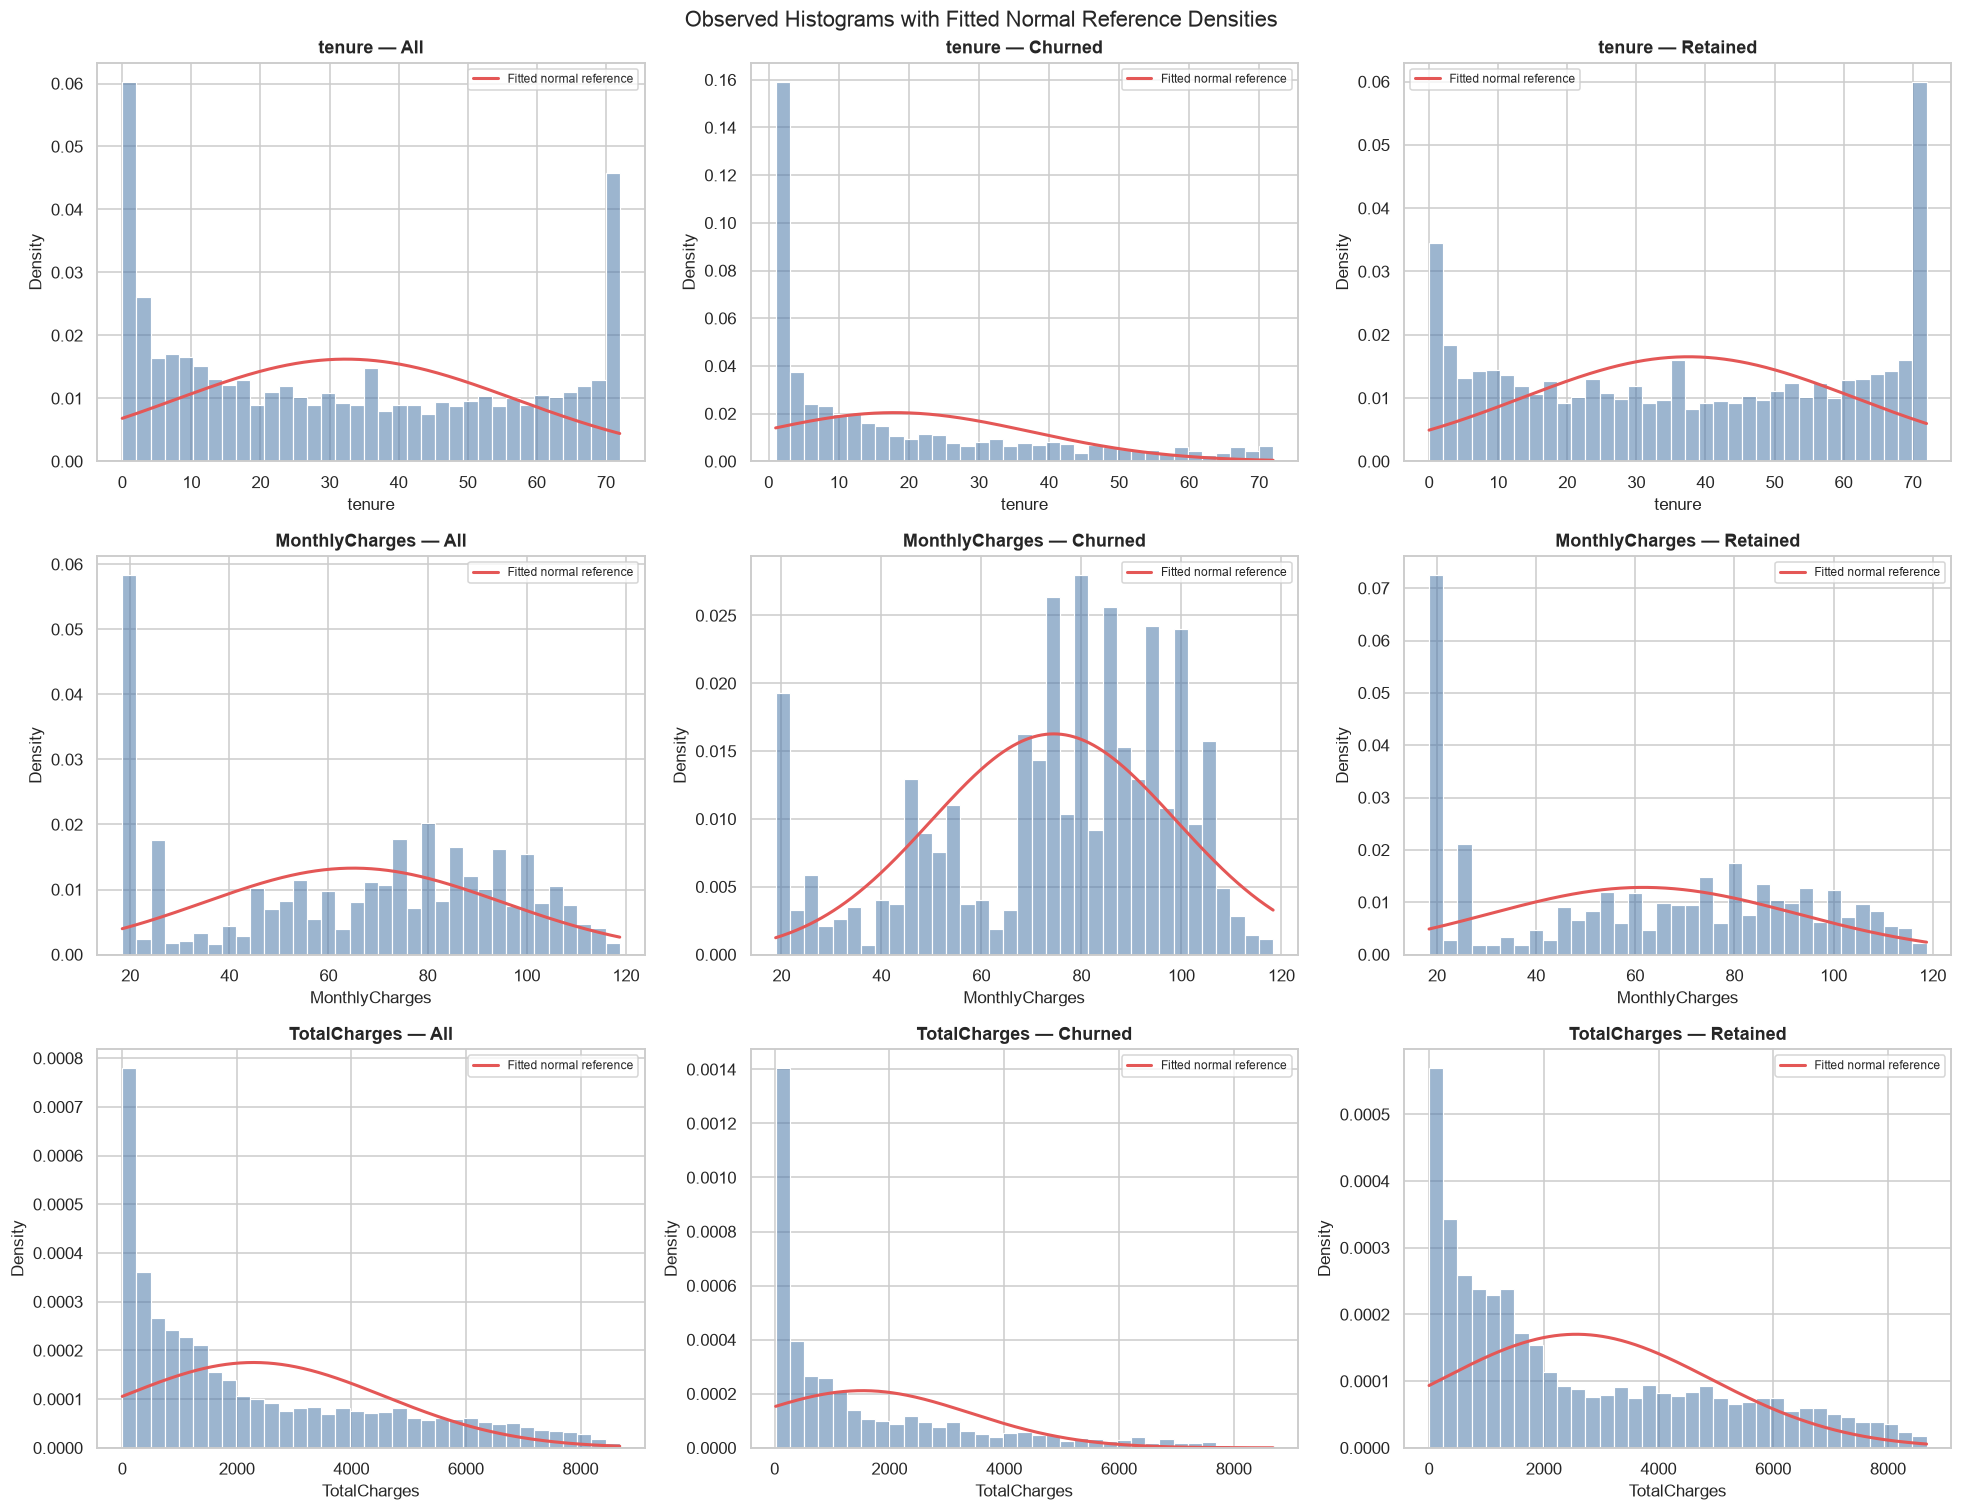

In [4]:
# ruff: noqa: E501
groups = [("All", pd.Series(True, index=df.index)), ("Churned", df[target_column].eq("Yes")), ("Retained", df[target_column].eq("No"))]
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for row_axis, feature in zip(axes, numerical_features, strict=True):
    for axis, (group, mask) in zip(row_axis, groups, strict=True):
        values = df.loc[mask, feature].to_numpy(float)
        sns.histplot(values, bins=35, stat="density", color="#4C78A8", alpha=0.55, ax=axis)
        x = np.linspace(values.min(), values.max(), 500)
        axis.plot(x, stats.norm.pdf(x, values.mean(), values.std(ddof=1)), color="#E45756", linewidth=2, label="Fitted normal reference")
        axis.set(title=f"{feature} — {group}", xlabel=feature, ylabel="Density")
        axis.legend(fontsize=8)
fig.suptitle("Observed Histograms with Fitted Normal Reference Densities")
fig.tight_layout()
plt.show()

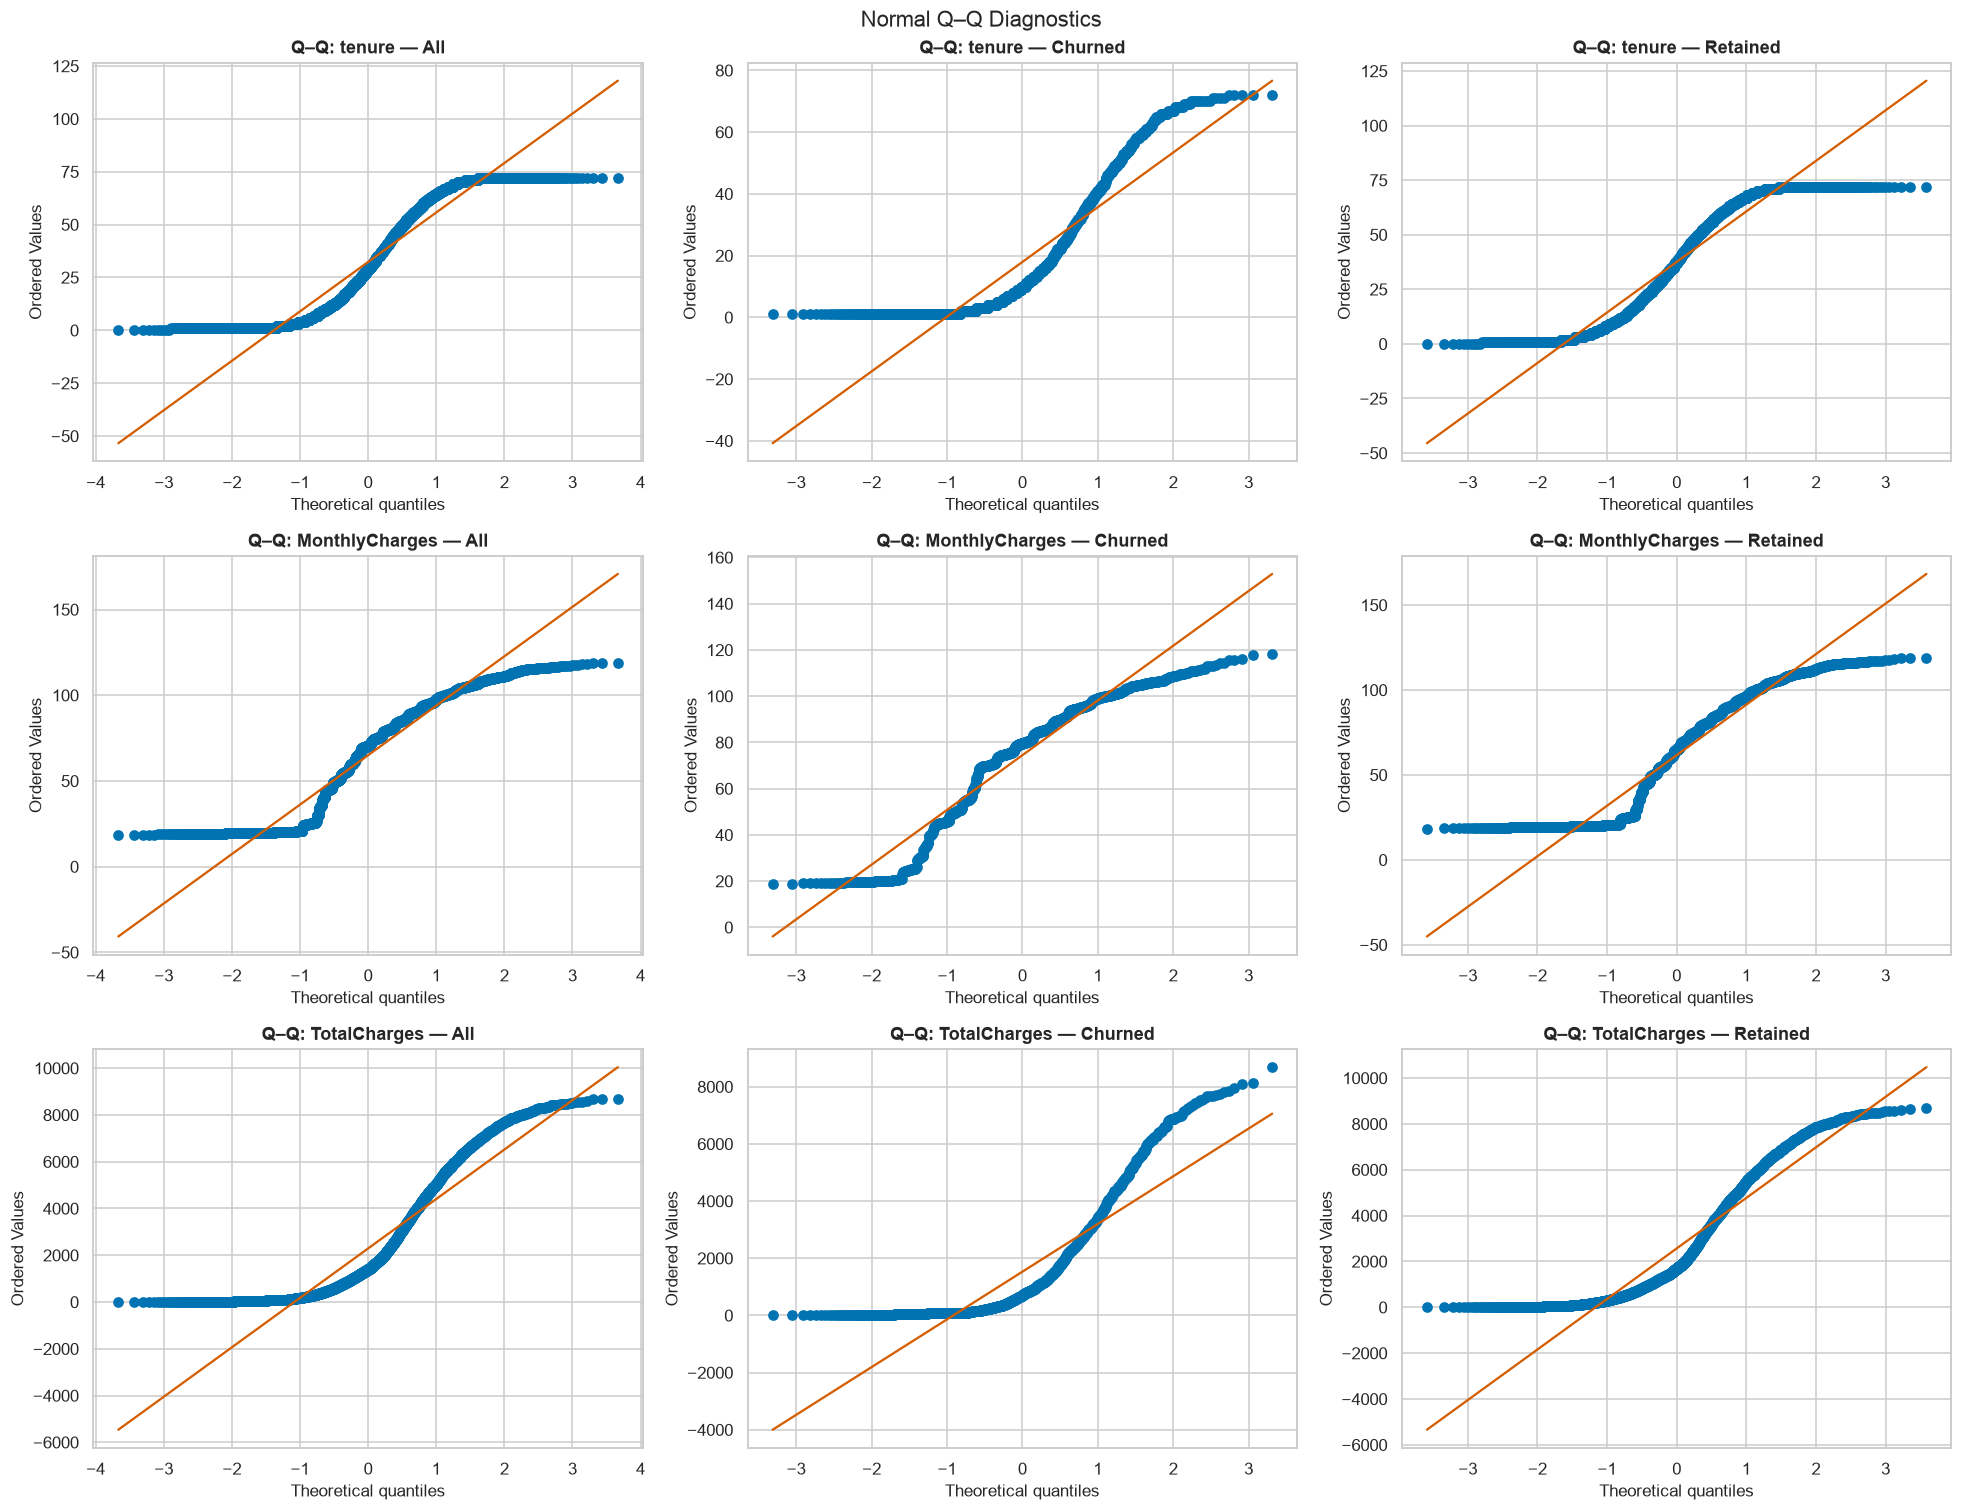

In [5]:
# ruff: noqa: E501
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for row_axis, feature in zip(axes, numerical_features, strict=True):
    for axis, (group, mask) in zip(row_axis, groups, strict=True):
        values = df.loc[mask, feature].to_numpy(float)
        stats.probplot(values, dist="norm", plot=axis)
        axis.set_title(f"Q–Q: {feature} — {group}")
fig.suptitle("Normal Q–Q Diagnostics")
fig.tight_layout()
plt.show()

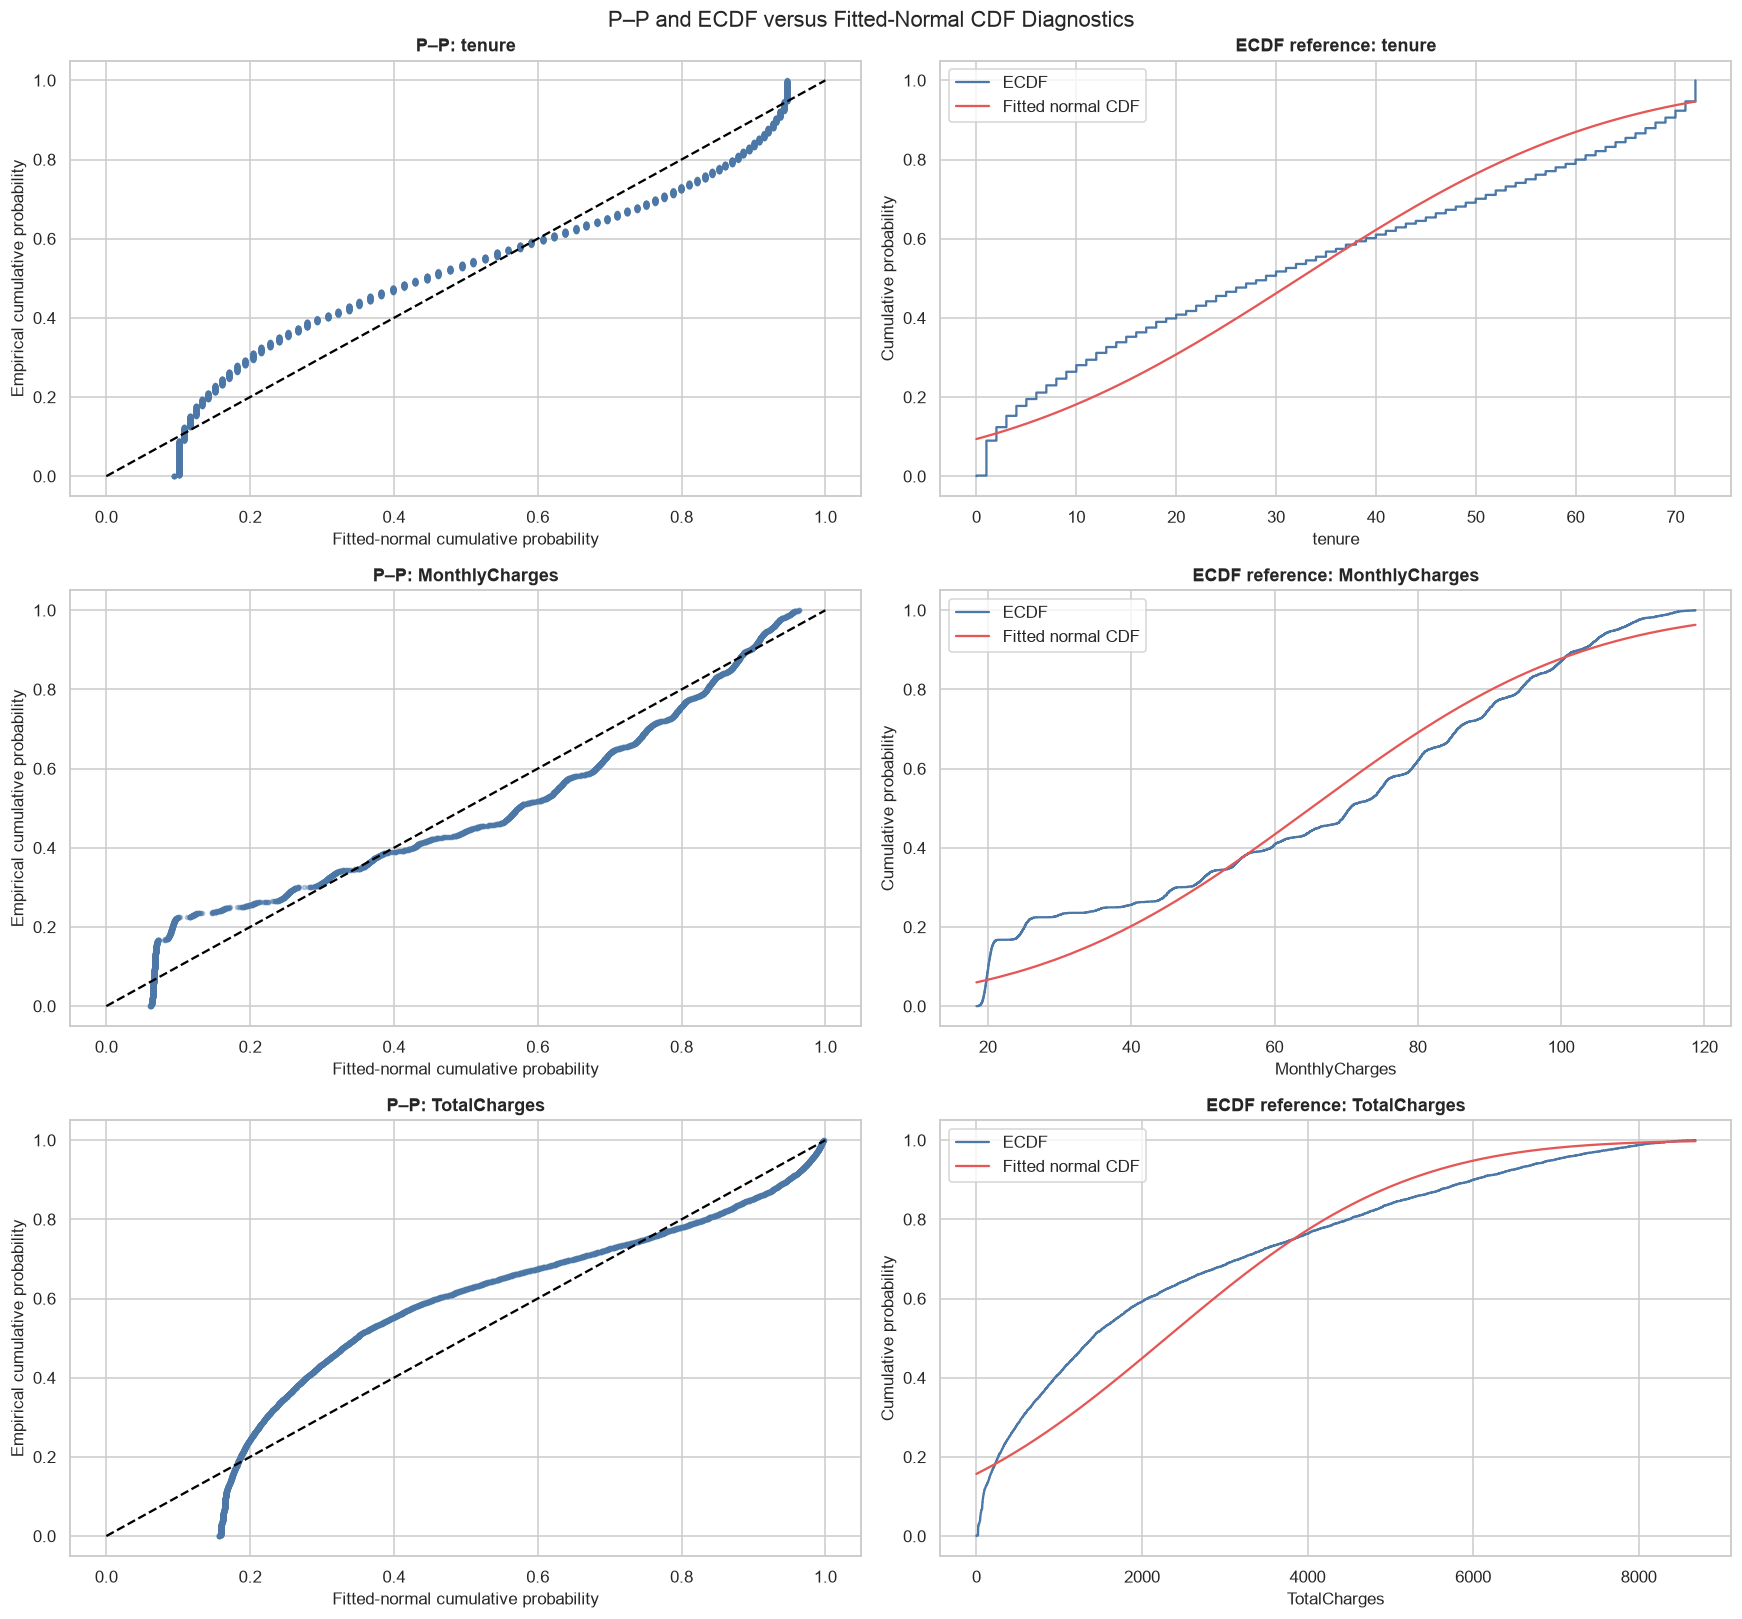

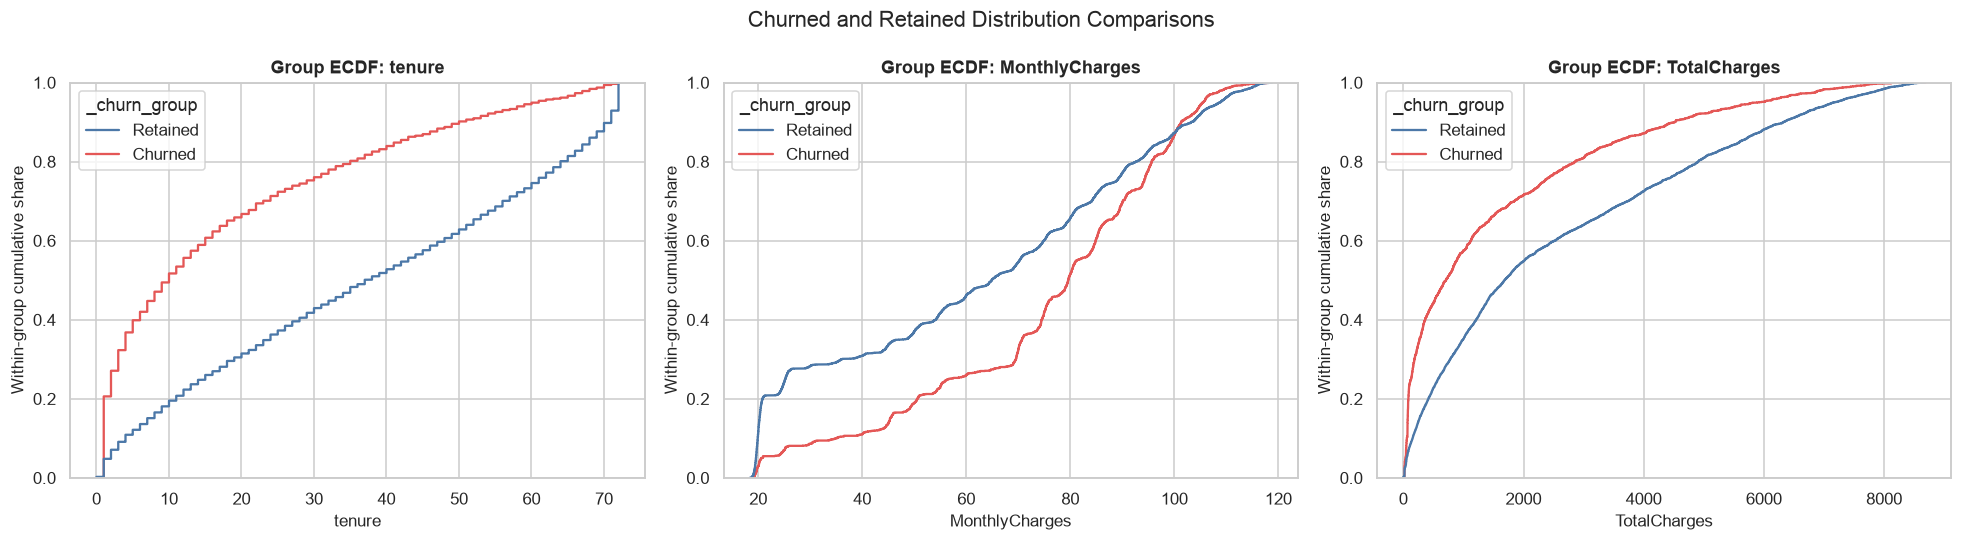

In [6]:
# ruff: noqa: E501
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
for row_axis, feature in zip(axes, numerical_features, strict=True):
    values = np.sort(df[feature].to_numpy(float))
    mean, sd = values.mean(), values.std(ddof=1)
    empirical_p = (np.arange(1, len(values) + 1) - 0.5) / len(values)
    theoretical_p = stats.norm.cdf(values, mean, sd)
    row_axis[0].scatter(theoretical_p, empirical_p, s=7, alpha=0.35, color="#4C78A8")
    row_axis[0].plot([0, 1], [0, 1], color="black", linestyle="--")
    row_axis[0].set(title=f"P–P: {feature}", xlabel="Fitted-normal cumulative probability", ylabel="Empirical cumulative probability")
    row_axis[1].step(values, np.arange(1, len(values) + 1) / len(values), where="post", color="#4C78A8", label="ECDF")
    row_axis[1].plot(values, stats.norm.cdf(values, mean, sd), color="#E45756", label="Fitted normal CDF")
    row_axis[1].set(title=f"ECDF reference: {feature}", xlabel=feature, ylabel="Cumulative probability")
    row_axis[1].legend()
fig.suptitle("P–P and ECDF versus Fitted-Normal CDF Diagnostics")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, feature in zip(axes, numerical_features, strict=True):
    sns.ecdfplot(data=analysis_df, x=feature, hue="_churn_group", palette={"Churned": "#E45756", "Retained": "#4C78A8"}, ax=axis)
    axis.set(title=f"Group ECDF: {feature}", ylabel="Within-group cumulative share")
fig.suptitle("Churned and Retained Distribution Comparisons")
fig.tight_layout()
plt.show()

## 5–8. Formal normality diagnostics

All hypotheses here are diagnostic: $H_0$ says the sample is compatible with a normal
population under the test model; $H_1$ says it is not. At exploratory $\alpha=.05$, a small
p-value indicates model mismatch—not importance, dependence, or sampling bias. Failure to
reject does not prove normality.

### Shapiro–Wilk

Shapiro–Wilk's $W$ compares the covariance-weighted ordered sample with what normal order
statistics predict; values closer to one are more normal-like. It is powerful but sensitive
to sample size, discreteness, and ties. SciPy warns that for $n>5{,}000$, $W$ may be useful
but the p-value may be inaccurate. Full statistics are retained and flagged; one
deterministic seed-42 subsample of exactly 5,000 is shown as sensitivity—not searched or
repeated until a favorable answer appears.

### D'Agostino–Pearson

This omnibus test combines transformed skewness and kurtosis components into
$K^2=Z_{skew}^2+Z_{kurt}^2$, asymptotically compared with $\chi^2_2$. It requires at least
eight observations and is sensitive to moment departures but less directly tail-weighted
than Anderson–Darling.

### Anderson–Darling

Anderson–Darling compares the empirical and fitted theoretical CDF with extra tail weight.
SciPy's installed normal-distribution API returns a statistic and tabulated critical values,
not a p-value. The notebook compares the statistic with the supplied 5% critical value and
does not fabricate or interpolate a p-value.

### Jarque–Bera

For sample size $n$, skewness $S$, and excess kurtosis $K$,

$$JB=\frac{n}{6}\left(S^2+\frac{K^2}{4}\right),$$

using an asymptotic $\chi^2_2$ reference. It is a moment-based large-sample diagnostic and
can have weak small-sample behavior. Unlike Shapiro's order-statistic approach and
Anderson–Darling's tail-weighted CDF approach, it only sees skewness and kurtosis.

In [7]:
# ruff: noqa: E501
def normality_diagnostics(values, feature, group, seed_offset=0):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    result = {"feature": feature, "group": group, "sample_size": n, "alpha": diagnostic_alpha}
    if n < 3 or np.ptp(values) == 0:
        return {**result, "status": "insufficient or constant", "shapiro_w": np.nan, "shapiro_p": np.nan, "shapiro_p_value_limited_n_gt_5000": n > 5000, "shapiro_sensitivity_n": np.nan, "shapiro_sensitivity_w": np.nan, "shapiro_sensitivity_p": np.nan, "dagostino_k2": np.nan, "dagostino_p": np.nan, "anderson_statistic": np.nan, "anderson_5pct_critical": np.nan, "anderson_reject_at_5pct": np.nan, "jarque_bera": np.nan, "jarque_bera_p": np.nan}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        shapiro = stats.shapiro(values)
    sensitivity_n = np.nan
    sensitivity_w = np.nan
    sensitivity_p = np.nan
    if n > 5000:
        local_rng = np.random.default_rng(random_state + seed_offset)
        selected = local_rng.choice(n, size=5000, replace=False)
        sensitivity = stats.shapiro(values[selected])
        sensitivity_n, sensitivity_w, sensitivity_p = 5000, sensitivity.statistic, sensitivity.pvalue
    if n >= 8:
        dagostino = stats.normaltest(values)
        dagostino_stat, dagostino_p = dagostino.statistic, dagostino.pvalue
    else:
        dagostino_stat, dagostino_p = np.nan, np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        anderson = stats.anderson(values, dist="norm")
    critical_index = int(np.argmin(np.abs(np.asarray(anderson.significance_level) - 5.0)))
    critical_5 = anderson.critical_values[critical_index]
    jb = stats.jarque_bera(values)
    return {**result, "status": "ok", "shapiro_w": shapiro.statistic, "shapiro_p": shapiro.pvalue, "shapiro_p_value_limited_n_gt_5000": n > 5000, "shapiro_sensitivity_n": sensitivity_n, "shapiro_sensitivity_w": sensitivity_w, "shapiro_sensitivity_p": sensitivity_p, "dagostino_k2": dagostino_stat, "dagostino_p": dagostino_p, "anderson_statistic": anderson.statistic, "anderson_5pct_critical": critical_5, "anderson_reject_at_5pct": bool(anderson.statistic > critical_5), "jarque_bera": jb.statistic, "jarque_bera_p": jb.pvalue}


normality_rows = []
offset = 0
for feature in numerical_features:
    normality_rows.append(normality_diagnostics(df[feature], feature, "All", offset)); offset += 1
    for group, churn_value in [("Churned", "Yes"), ("Retained", "No")]:
        normality_rows.append(normality_diagnostics(df.loc[df[target_column].eq(churn_value), feature], feature, group, offset)); offset += 1
normality_comparison = pd.DataFrame(normality_rows)
display(normality_comparison)

constant_safety = normality_diagnostics(np.ones(20), "synthetic constant", "safety check")
insufficient_safety = normality_diagnostics([1.0, 2.0], "synthetic insufficient", "safety check")
display(pd.DataFrame([constant_safety, insufficient_safety]))

,feature,group,sample_size,alpha,status,shapiro_w,shapiro_p,shapiro_p_value_limited_n_gt_5000,shapiro_sensitivity_n,shapiro_sensitivity_w,shapiro_sensitivity_p,dagostino_k2,dagostino_p,anderson_statistic,anderson_5pct_critical,anderson_reject_at_5pct,jarque_bera,jarque_bera_p
0,tenure,All,5634,0.050000,ok,0.903520,0.000000,True,"5,000.000000",0.903511,0.000000,"62,447.164710",0.000000,162.794677,0.752000,True,505.559616,0.000000
1,tenure,Churned,1495,0.050000,ok,0.819702,0.000000,False,NaN,NaN,NaN,222.442922,0.000000,96.503529,0.752000,True,331.976886,0.000000
2,tenure,Retained,4139,0.050000,ok,0.917520,0.000000,False,NaN,NaN,NaN,"37,312.449249",0.000000,96.627007,0.752000,True,345.394992,0.000000
3,MonthlyCharges,All,5634,0.050000,ok,0.921557,0.000000,True,"5,000.000000",0.920822,0.000000,"7,264.525654",0.000000,134.940988,0.752000,True,412.646714,0.000000
4,MonthlyCharges,Churned,1495,0.050000,ok,0.928302,0.000000,False,NaN,NaN,NaN,120.464234,0.000000,33.486202,0.752000,True,143.430553,0.000000
5,MonthlyCharges,Retained,4139,0.050000,ok,0.914011,0.000000,False,NaN,NaN,NaN,"149,894.862914",0.000000,109.310043,0.752000,True,313.954514,0.000000
6,TotalCharges,All,5634,0.050000,ok,0.860764,0.000000,True,"5,000.000000",0.858874,0.000000,645.221835,0.000000,275.196639,0.752000,True,879.879043,0.000000
7,TotalCharges,Churned,1495,0.050000,ok,0.780388,0.000000,False,NaN,NaN,NaN,370.831329,0.000000,116.854507,0.752000,True,709.881289,0.000000
8,TotalCharges,Retained,4139,0.050000,ok,0.883661,0.000000,False,NaN,NaN,NaN,456.447011,0.000000,166.645102,0.752000,True,499.007959,0.000000


,feature,group,sample_size,alpha,status,shapiro_w,shapiro_p,shapiro_p_value_limited_n_gt_5000,shapiro_sensitivity_n,shapiro_sensitivity_w,shapiro_sensitivity_p,dagostino_k2,dagostino_p,anderson_statistic,anderson_5pct_critical,anderson_reject_at_5pct,jarque_bera,jarque_bera_p
0,synthetic constant,safety check,20,0.050000,insufficient or constant,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,synthetic insufficient,safety check,2,0.050000,insufficient or constant,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# ruff: noqa: E501
all_view = normality_comparison[normality_comparison["group"].eq("All")]
display(Markdown(
    "### Actual telecom diagnostic interpretation\n\n"
    + "\n".join(
        f"- **{row.feature}:** Shapiro W={row.shapiro_w:.4f} (full-sample p={row.shapiro_p:.3g}, flagged n>5,000; deterministic n=5,000 sensitivity p={row.shapiro_sensitivity_p:.3g}); D’Agostino K²={row.dagostino_k2:.2f}, p={row.dagostino_p:.3g}; Anderson A²={row.anderson_statistic:.2f} versus 5% critical {row.anderson_5pct_critical:.3f}; Jarque–Bera={row.jarque_bera:.2f}, p={row.jarque_bera_p:.3g}."
        for _, row in all_view.iterrows()
    )
    + "\n\nAll four diagnostics and the graphical evidence indicate substantial mismatch with a single fitted normal reference. This does not by itself invalidate large-sample mean inference or establish dependence, bias, or business importance."
))

### Actual telecom diagnostic interpretation

- **tenure:** Shapiro W=0.9035 (full-sample p=9.36e-51, flagged n>5,000; deterministic n=5,000 sensitivity p=1.31e-48); D’Agostino K²=62447.16, p=0; Anderson A²=162.79 versus 5% critical 0.752; Jarque–Bera=505.56, p=1.66e-110.
- **MonthlyCharges:** Shapiro W=0.9216 (full-sample p=2.88e-47, flagged n>5,000; deterministic n=5,000 sensitivity p=2.31e-45); D’Agostino K²=7264.53, p=0; Anderson A²=134.94 versus 5% critical 0.752; Jarque–Bera=412.65, p=2.48e-90.
- **TotalCharges:** Shapiro W=0.8608 (full-sample p=2.98e-57, flagged n>5,000; deterministic n=5,000 sensitivity p=3.49e-55); D’Agostino K²=645.22, p=7.8e-141; Anderson A²=275.20 versus 5% critical 0.752; Jarque–Bera=879.88, p=8.64e-192.

All four diagnostics and the graphical evidence indicate substantial mismatch with a single fitted normal reference. This does not by itself invalidate large-sample mean inference or establish dependence, bias, or business importance.

## 9. Sample-size sensitivity with known synthetic distributions

For each distribution and $n\in\{30,100,500,1000\}$, 500 independent seed-controlled
samples are tested with Shapiro–Wilk, D'Agostino–Pearson, and Jarque–Bera. Rejection
frequency estimates Type I error for the correctly specified normal null and detection power
for nonnormal alternatives. Its Monte Carlo standard error is
$\sqrt{\hat r(1-\hat r)/500}$. Mild skew uses a skew-normal distribution; strong skew uses
a lognormal; bimodality uses an equal two-normal mixture. These are synthetic demonstrations,
not known truths about telecom customers.

,distribution,sample_size,method,rejection_frequency,monte_carlo_se,repetitions
0,Normal,30,Shapiro–Wilk,0.070000,0.011411,500
1,Normal,30,D’Agostino–Pearson,0.068000,0.011258,500
2,Normal,30,Jarque–Bera,0.036000,0.008331,500
3,Normal,100,Shapiro–Wilk,0.062000,0.010785,500
4,Normal,100,D’Agostino–Pearson,0.084000,0.012405,500
5,Normal,100,Jarque–Bera,0.052000,0.009929,500
6,Normal,500,Shapiro–Wilk,0.070000,0.011411,500
7,Normal,500,D’Agostino–Pearson,0.058000,0.010453,500
8,Normal,500,Jarque–Bera,0.056000,0.010282,500
9,Normal,1000,Shapiro–Wilk,0.038000,0.008551,500


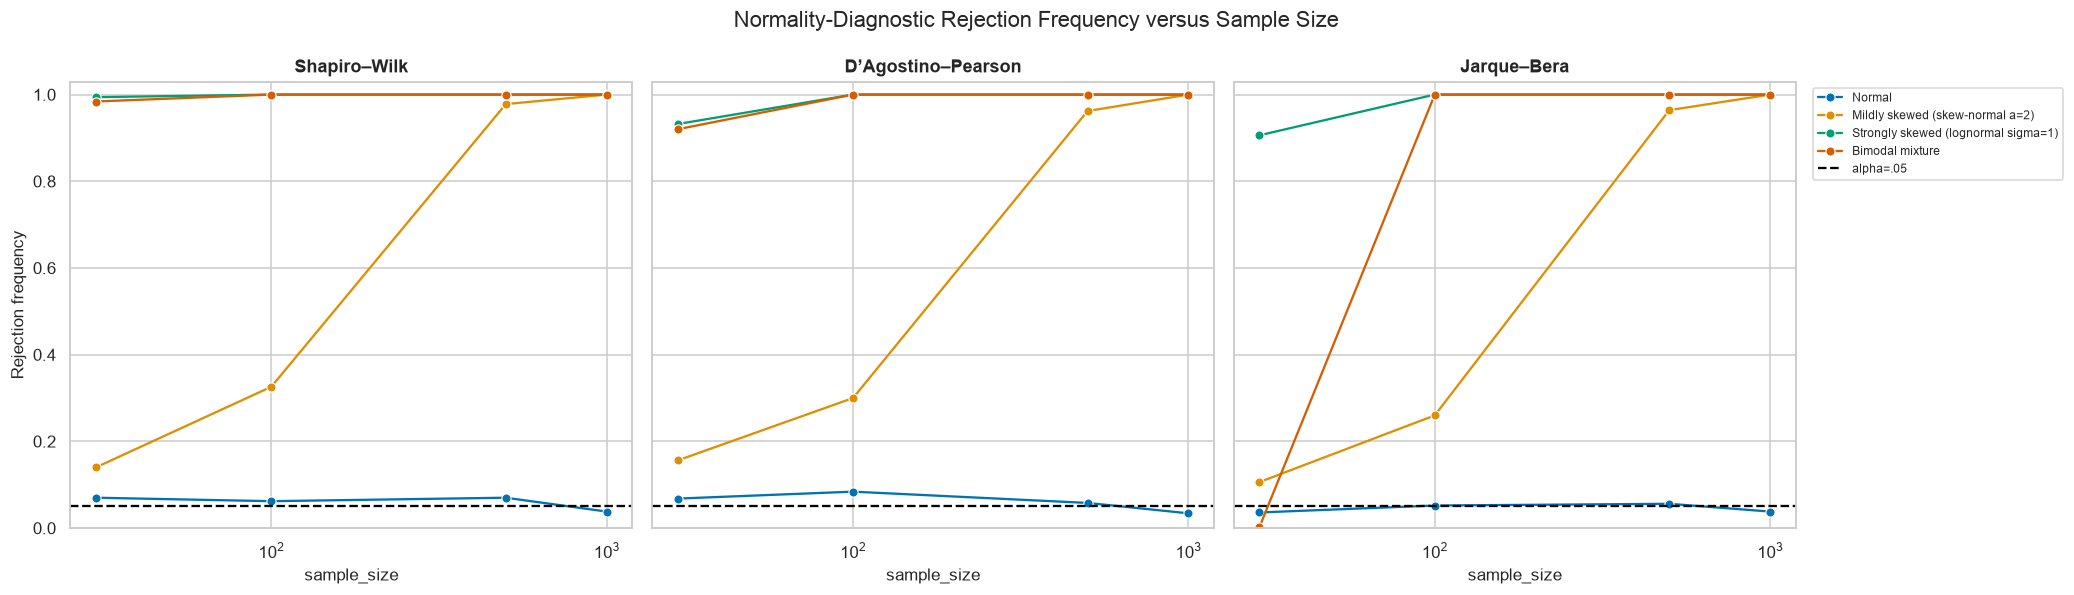

In [9]:
# ruff: noqa: E501
simulation_rng = np.random.default_rng(random_state)
simulation_repetitions = 500
simulation_rows = []


def generate_synthetic(name, repetitions, sample_size):
    if name == "Normal":
        return simulation_rng.normal(size=(repetitions, sample_size))
    if name == "Mildly skewed (skew-normal a=2)":
        return stats.skewnorm.rvs(a=2, size=(repetitions, sample_size), random_state=simulation_rng)
    if name == "Strongly skewed (lognormal sigma=1)":
        return simulation_rng.lognormal(mean=0, sigma=1, size=(repetitions, sample_size))
    selectors = simulation_rng.random((repetitions, sample_size)) < 0.5
    return simulation_rng.normal(-1.75, 0.65, size=(repetitions, sample_size)) * selectors + simulation_rng.normal(1.75, 0.65, size=(repetitions, sample_size)) * (~selectors)


synthetic_distributions = ["Normal", "Mildly skewed (skew-normal a=2)", "Strongly skewed (lognormal sigma=1)", "Bimodal mixture"]
for distribution in synthetic_distributions:
    for sample_size in [30, 100, 500, 1000]:
        samples = generate_synthetic(distribution, simulation_repetitions, sample_size)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            shapiro_p = stats.shapiro(samples, axis=1).pvalue
        dagostino_p = stats.normaltest(samples, axis=1).pvalue
        jb_p = stats.jarque_bera(samples, axis=1).pvalue
        for method, p_values in [("Shapiro–Wilk", shapiro_p), ("D’Agostino–Pearson", dagostino_p), ("Jarque–Bera", jb_p)]:
            rejection = np.mean(p_values < diagnostic_alpha)
            simulation_rows.append({"distribution": distribution, "sample_size": sample_size, "method": method, "rejection_frequency": rejection, "monte_carlo_se": np.sqrt(rejection * (1 - rejection) / simulation_repetitions), "repetitions": simulation_repetitions})

sample_size_simulation = pd.DataFrame(simulation_rows)
display(sample_size_simulation)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True)
for axis, method in zip(axes, ["Shapiro–Wilk", "D’Agostino–Pearson", "Jarque–Bera"], strict=True):
    view = sample_size_simulation[sample_size_simulation["method"].eq(method)]
    sns.lineplot(data=view, x="sample_size", y="rejection_frequency", hue="distribution", marker="o", ax=axis)
    axis.axhline(diagnostic_alpha, color="black", linestyle="--", label="alpha=.05")
    axis.set(title=method, xscale="log", ylim=(0, 1.03), ylabel="Rejection frequency")
    if method != "Jarque–Bera":
        axis.get_legend().remove()
    else:
        axis.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.suptitle("Normality-Diagnostic Rejection Frequency versus Sample Size")
fig.tight_layout()
plt.show()

Under a true normal generator, rejection should fluctuate near 5%, not equal zero. Under
nonnormal generators, rejection frequency is diagnostic power: it generally rises with
sample size. Small samples can miss consequential mismatch; large samples can detect minor
departures that have little practical effect on robust mean inference. Thus p-values must be
read alongside shape, magnitude, estimand, and method robustness. Failure to reject is not
proof of normality.

## 10. Homogeneity-of-variance diagnostics: churned versus retained

For each feature, $H_0$ is equal population variance and $H_1$ is unequal variance.
**Levene centered on the mean** tests absolute deviations from group means. The
**Brown–Forsythe** variant uses medians and is generally more robust to skew and outliers.
**Bartlett** is efficient under normality but highly sensitive to nonnormality, so its
telecom results are explicitly flagged as potentially unreliable.

Unequal sizes and variances can distort pooled Student t inference. A preliminary variance
test should not automatically switch methods because this data-dependent gate changes error
behavior and low-power variance tests do not prove equality. Welch's independent t method
directly allows unequal variances and is a defensible default for mean differences.

,feature,comparison,group_1_n,group_2_n,status,group_1_variance,group_2_variance,group_1_sd,group_2_sd,variance_ratio_group1_over_group2,sd_ratio_group1_over_group2,levene_mean_statistic,levene_mean_p,brown_forsythe_statistic,brown_forsythe_p,bartlett_statistic,bartlett_p,bartlett_reliability
0,tenure,Churned ÷ retained,1495,4139,ok,381.661310,582.939305,19.536154,24.144136,0.654719,0.809147,269.884502,0.000000,334.125823,0.000000,91.736811,0.000000,potentially unreliable: substantial nonnormality
1,MonthlyCharges,Churned ÷ retained,1495,4139,ok,601.176790,966.219555,24.518907,31.084072,0.622195,0.788793,293.661941,0.000000,292.348302,0.000000,114.108715,0.000000,potentially unreliable: substantial nonnormality
2,TotalCharges,Churned ÷ retained,1495,4139,ok,"3,556,482.219958","5,489,606.641280","1,885.863786","2,342.990961",0.647857,0.804896,206.416967,0.000000,138.157035,0.000000,96.179508,0.000000,potentially unreliable: substantial nonnormality


,feature,comparison,group_1_n,group_2_n,status,group_1_variance,group_2_variance,group_1_sd,group_2_sd,variance_ratio_group1_over_group2,sd_ratio_group1_over_group2,levene_mean_statistic,levene_mean_p,brown_forsythe_statistic,brown_forsythe_p,bartlett_statistic,bartlett_p,bartlett_reliability
0,synthetic,safety check,20,20,insufficient or constant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not applicable


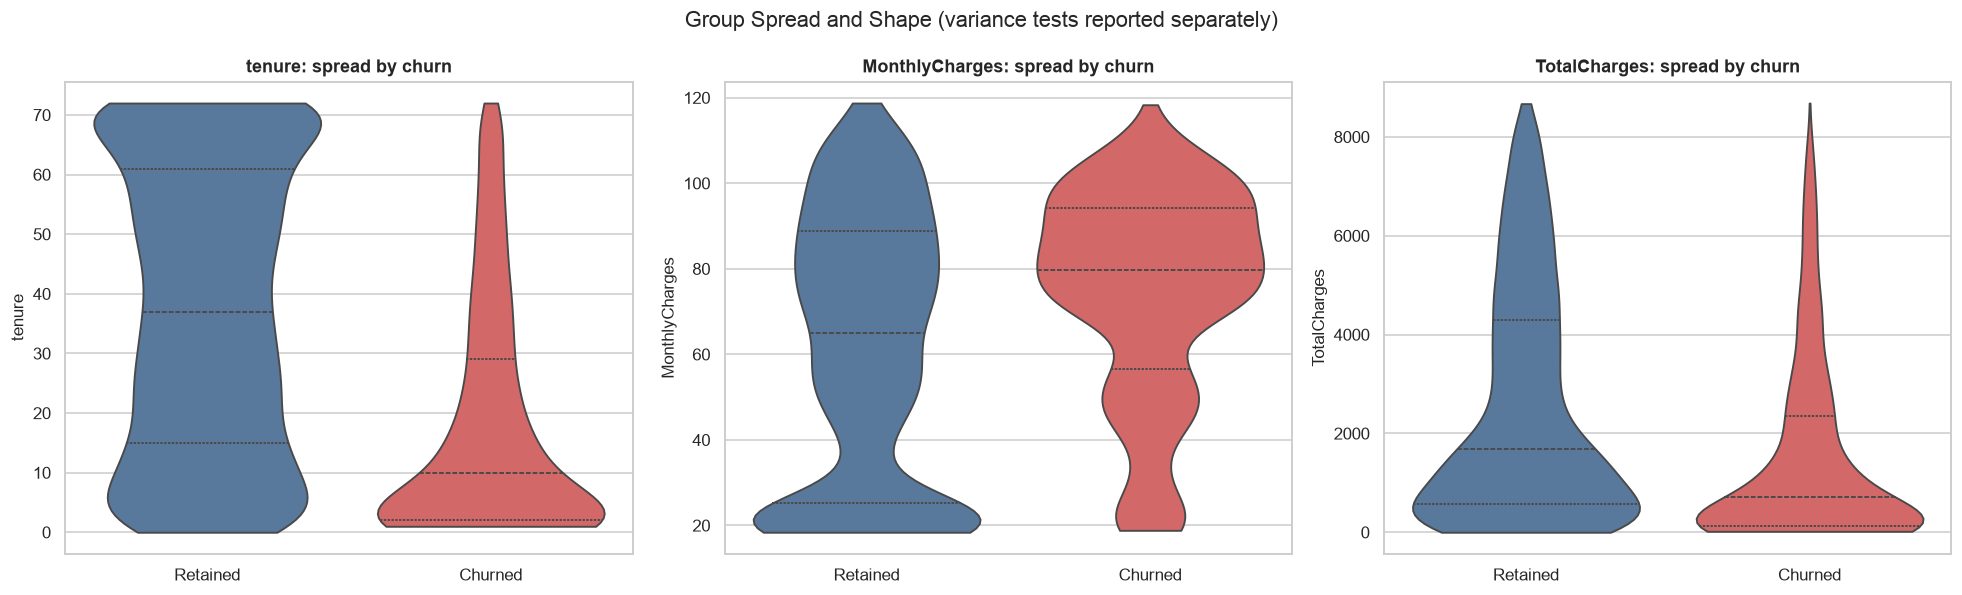

In [10]:
# ruff: noqa: E501
def variance_diagnostics(group_1, group_2, feature, comparison):
    a = np.asarray(group_1, float); b = np.asarray(group_2, float)
    a = a[np.isfinite(a)]; b = b[np.isfinite(b)]
    result = {"feature": feature, "comparison": comparison, "group_1_n": len(a), "group_2_n": len(b)}
    if min(len(a), len(b)) < 2 or np.ptp(a) == 0 or np.ptp(b) == 0:
        return {**result, "status": "insufficient or constant", "group_1_variance": np.nan, "group_2_variance": np.nan, "group_1_sd": np.nan, "group_2_sd": np.nan, "variance_ratio_group1_over_group2": np.nan, "sd_ratio_group1_over_group2": np.nan, "levene_mean_statistic": np.nan, "levene_mean_p": np.nan, "brown_forsythe_statistic": np.nan, "brown_forsythe_p": np.nan, "bartlett_statistic": np.nan, "bartlett_p": np.nan, "bartlett_reliability": "not applicable"}
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    levene_mean = stats.levene(a, b, center="mean")
    brown_forsythe = stats.levene(a, b, center="median")
    bartlett = stats.bartlett(a, b)
    return {**result, "status": "ok", "group_1_variance": v1, "group_2_variance": v2, "group_1_sd": np.sqrt(v1), "group_2_sd": np.sqrt(v2), "variance_ratio_group1_over_group2": v1 / v2, "sd_ratio_group1_over_group2": np.sqrt(v1 / v2), "levene_mean_statistic": levene_mean.statistic, "levene_mean_p": levene_mean.pvalue, "brown_forsythe_statistic": brown_forsythe.statistic, "brown_forsythe_p": brown_forsythe.pvalue, "bartlett_statistic": bartlett.statistic, "bartlett_p": bartlett.pvalue, "bartlett_reliability": "potentially unreliable: substantial nonnormality"}


variance_rows = []
for feature in numerical_features:
    variance_rows.append(variance_diagnostics(df.loc[df[target_column].eq("Yes"), feature], df.loc[df[target_column].eq("No"), feature], feature, "Churned ÷ retained"))
variance_comparison = pd.DataFrame(variance_rows)
display(variance_comparison)

constant_variance_safety = variance_diagnostics(np.ones(20), np.arange(20), "synthetic", "safety check")
display(pd.DataFrame([constant_variance_safety]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for axis, feature in zip(axes, numerical_features, strict=True):
    sns.violinplot(data=analysis_df, x="_churn_group", y=feature, hue="_churn_group", palette={"Churned": "#E45756", "Retained": "#4C78A8"}, inner="quartile", cut=0, legend=False, ax=axis)
    axis.set(title=f"{feature}: spread by churn", xlabel="", ylabel=feature)
fig.suptitle("Group Spread and Shape (variance tests reported separately)")
fig.tight_layout()
plt.show()

## 11. Multiple-group assumption diagnostics

These four descriptive views assess shape and variance heterogeneity before any later
multi-group outcome test. Standardized Q–Q points isolate shape from location and scale.
Brown–Forsythe p-values are assumption diagnostics only; no ANOVA, Welch ANOVA, or
Kruskal–Wallis test is performed.

In [11]:
# ruff: noqa: E501
multi_group_specs = [("tenure", "Contract"), ("MonthlyCharges", "InternetService"), ("tenure", "PaymentMethod"), ("TotalCharges", "Contract")]
multi_group_rows = []
multi_group_variance_rows = []
for feature, dimension in multi_group_specs:
    arrays = []
    for category, group in df.groupby(dimension, observed=True):
        values = group[feature].to_numpy(float)
        arrays.append(values)
        multi_group_rows.append({"feature": feature, "dimension": dimension, "category": str(category), "sample_size": len(values), "mean": values.mean(), "median": np.median(values), "standard_deviation": values.std(ddof=1), "variance": values.var(ddof=1), "skewness": stats.skew(values, bias=False), "excess_kurtosis": stats.kurtosis(values, fisher=True, bias=False), "unique_values": np.unique(values).size})
    bf = stats.levene(*arrays, center="median")
    multi_group_variance_rows.append({"feature": feature, "dimension": dimension, "group_count": len(arrays), "brown_forsythe_statistic": bf.statistic, "brown_forsythe_p": bf.pvalue, "exploratory_unadjusted": True})
multi_group_descriptives = pd.DataFrame(multi_group_rows)
multi_group_variance = pd.DataFrame(multi_group_variance_rows)
display(multi_group_descriptives)
display(multi_group_variance)

,feature,dimension,category,sample_size,mean,median,standard_deviation,variance,skewness,excess_kurtosis,unique_values
0,tenure,Contract,Month-to-month,3095,18.115347,12.000000,17.723180,314.111125,1.038907,0.121194,72
1,tenure,Contract,One year,1178,41.522920,43.000000,19.378138,375.512218,-0.258077,-1.040151,73
2,tenure,Contract,Two year,1361,56.779574,64.000000,18.224980,332.149906,-1.356162,0.930204,73
3,MonthlyCharges,InternetService,DSL,1934,58.350698,56.350000,16.095214,259.055929,0.036794,-0.589892,851
4,MonthlyCharges,InternetService,Fiber optic,2493,91.517228,91.850000,12.667032,160.453689,-0.018074,-0.989216,814
5,MonthlyCharges,InternetService,No,1207,21.036785,20.100000,2.152269,4.632261,1.307424,0.083112,120
6,tenure,PaymentMethod,Bank transfer (automatic),1246,43.211878,47.000000,23.203241,538.390413,-0.330711,-1.252682,73
7,tenure,PaymentMethod,Credit card (automatic),1215,43.312757,47.000000,23.297290,542.763717,-0.331960,-1.262643,73
8,tenure,PaymentMethod,Electronic check,1877,25.496537,18.000000,22.557782,508.853533,0.617747,-0.948048,72
9,tenure,PaymentMethod,Mailed check,1296,21.554012,14.000000,21.308476,454.051134,0.899317,-0.442547,73


,feature,dimension,group_count,brown_forsythe_statistic,brown_forsythe_p,exploratory_unadjusted
0,tenure,Contract,3,25.697128,0.000000,True
1,MonthlyCharges,InternetService,3,"1,054.000594",0.000000,True
2,tenure,PaymentMethod,4,17.380043,0.000000,True
3,TotalCharges,Contract,3,445.464180,0.000000,True


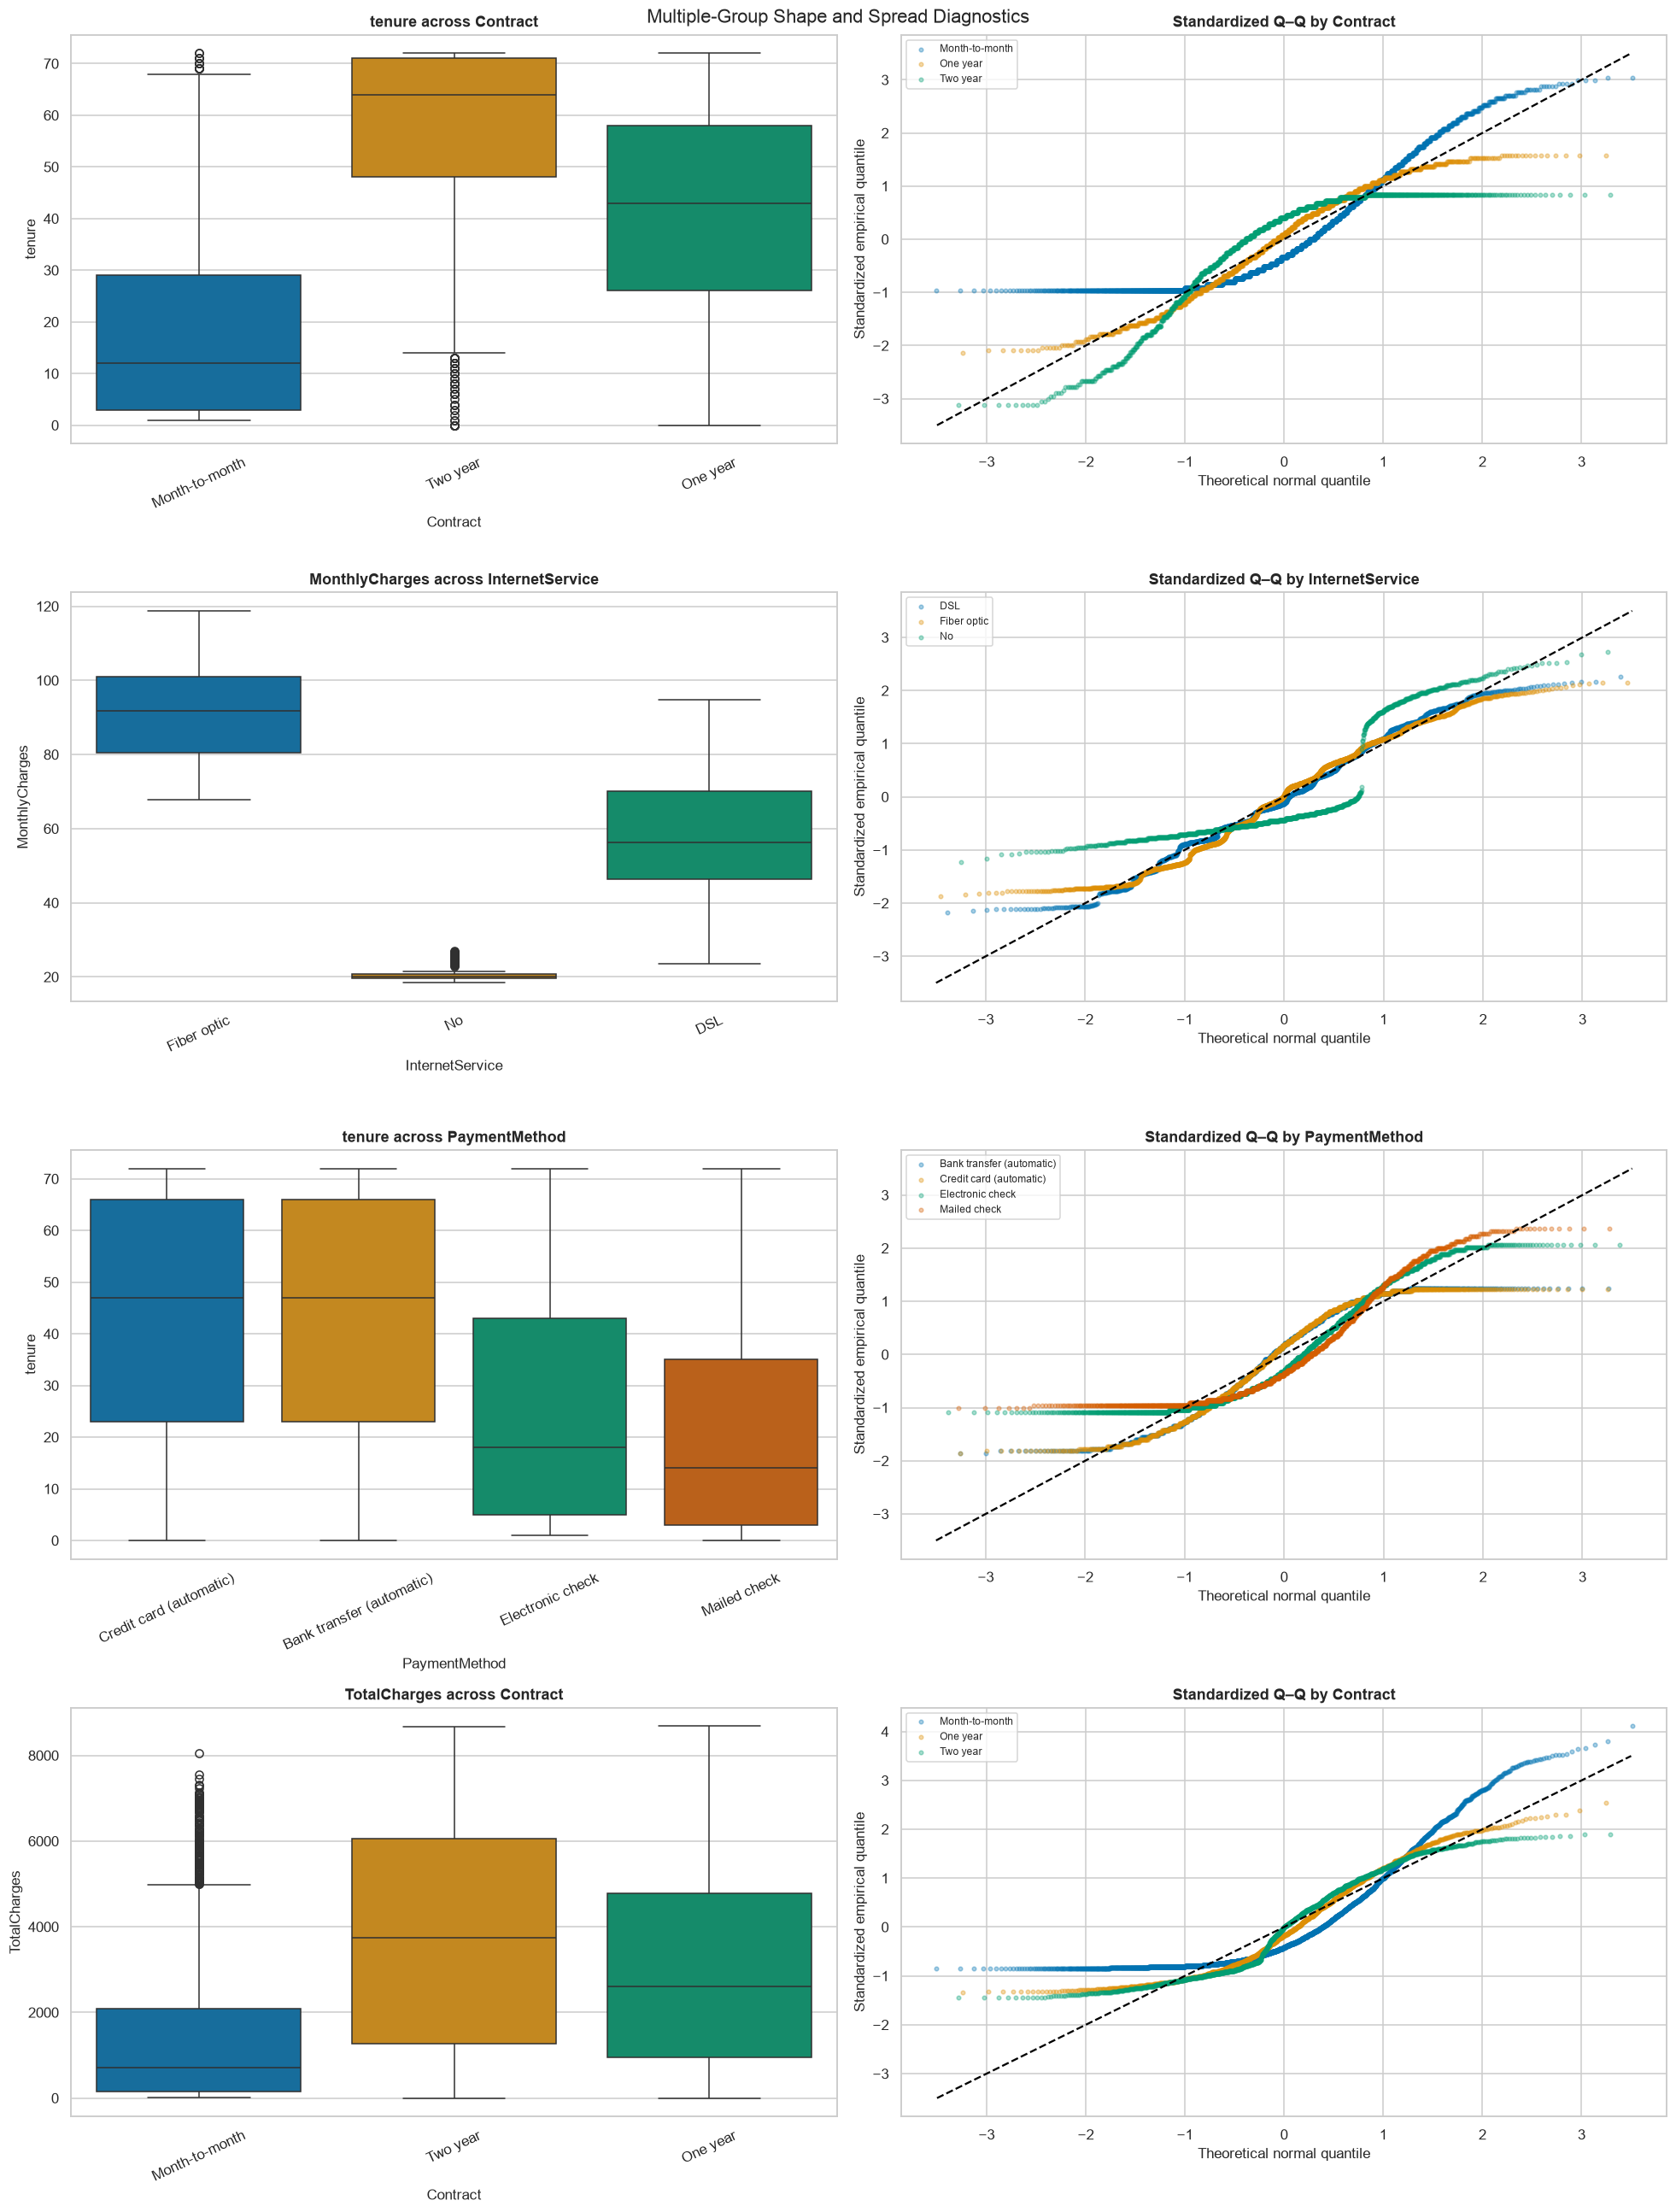

In [12]:
# ruff: noqa: E501
fig, axes = plt.subplots(4, 2, figsize=(18, 24))
for row_axes, (feature, dimension) in zip(axes, multi_group_specs, strict=True):
    sns.boxplot(data=df, x=dimension, y=feature, hue=dimension, legend=False, ax=row_axes[0])
    row_axes[0].set(title=f"{feature} across {dimension}", xlabel=dimension, ylabel=feature)
    row_axes[0].tick_params(axis="x", rotation=25)
    for category, group in df.groupby(dimension, observed=True):
        values = group[feature].to_numpy(float)
        standardized = (values - values.mean()) / values.std(ddof=1)
        osm, osr = stats.probplot(standardized, dist="norm", fit=False)
        row_axes[1].scatter(osm, osr, s=9, alpha=0.35, label=str(category))
    limits = [-3.5, 3.5]
    row_axes[1].plot(limits, limits, color="black", linestyle="--")
    row_axes[1].set(title=f"Standardized Q–Q by {dimension}", xlabel="Theoretical normal quantile", ylabel="Standardized empirical quantile")
    row_axes[1].legend(fontsize=8)
fig.suptitle("Multiple-Group Shape and Spread Diagnostics")
fig.tight_layout()
plt.show()

## 12. Notebook-local transformation sensitivity

For nonnegative values, $\log(1+x)$ compresses large observations more than $\sqrt{x}$.
The table compares overall skewness/kurtosis and churn-group Brown–Forsythe diagnostics on
each scale. Transformations do not guarantee normality; bounded and multimodal variables
can remain nonnormal. A transformed mean or difference is a different estimand on a
different scale, so interpretation changes.

Predictive models generally do not require normally distributed inputs. Transformations
should follow modelling objectives—linearity, variance stabilization, numerical behavior,
or domain meaning—not a quest to make a diagnostic p-value exceed .05. Nothing is written
back to the source DataFrame or persisted as production preprocessing.

,feature,transformation,skewness,excess_kurtosis,churned_variance,retained_variance,variance_ratio_churned_over_retained,brown_forsythe_statistic,brown_forsythe_p
0,tenure,Original,0.240564,-1.386617,381.661310,582.939305,0.654719,334.125823,0.000000
1,tenure,log1p,-0.777402,-0.639239,1.430450,1.058521,1.351367,158.122667,0.000000
2,tenure,Square root,-0.235952,-1.280019,5.166545,5.466583,0.945114,2.479021,0.115430
3,MonthlyCharges,Original,-0.235174,-1.239674,601.176790,966.219555,0.622195,292.348302,0.000000
4,MonthlyCharges,log1p,-0.739897,-0.929216,0.188900,0.368482,0.512644,336.051130,0.000000
5,MonthlyCharges,Square root,-0.502618,-1.129856,2.575751,4.553125,0.565711,336.134725,0.000000
6,TotalCharges,Original,0.961554,-0.226692,"3,556,482.219958","5,489,606.641280",0.647857,138.157035,0.000000
7,TotalCharges,log1p,-0.836735,0.147502,2.713526,2.219001,1.222859,83.735863,0.000000
8,TotalCharges,Square root,0.303221,-1.064030,519.435838,598.022644,0.868589,26.809522,0.000000


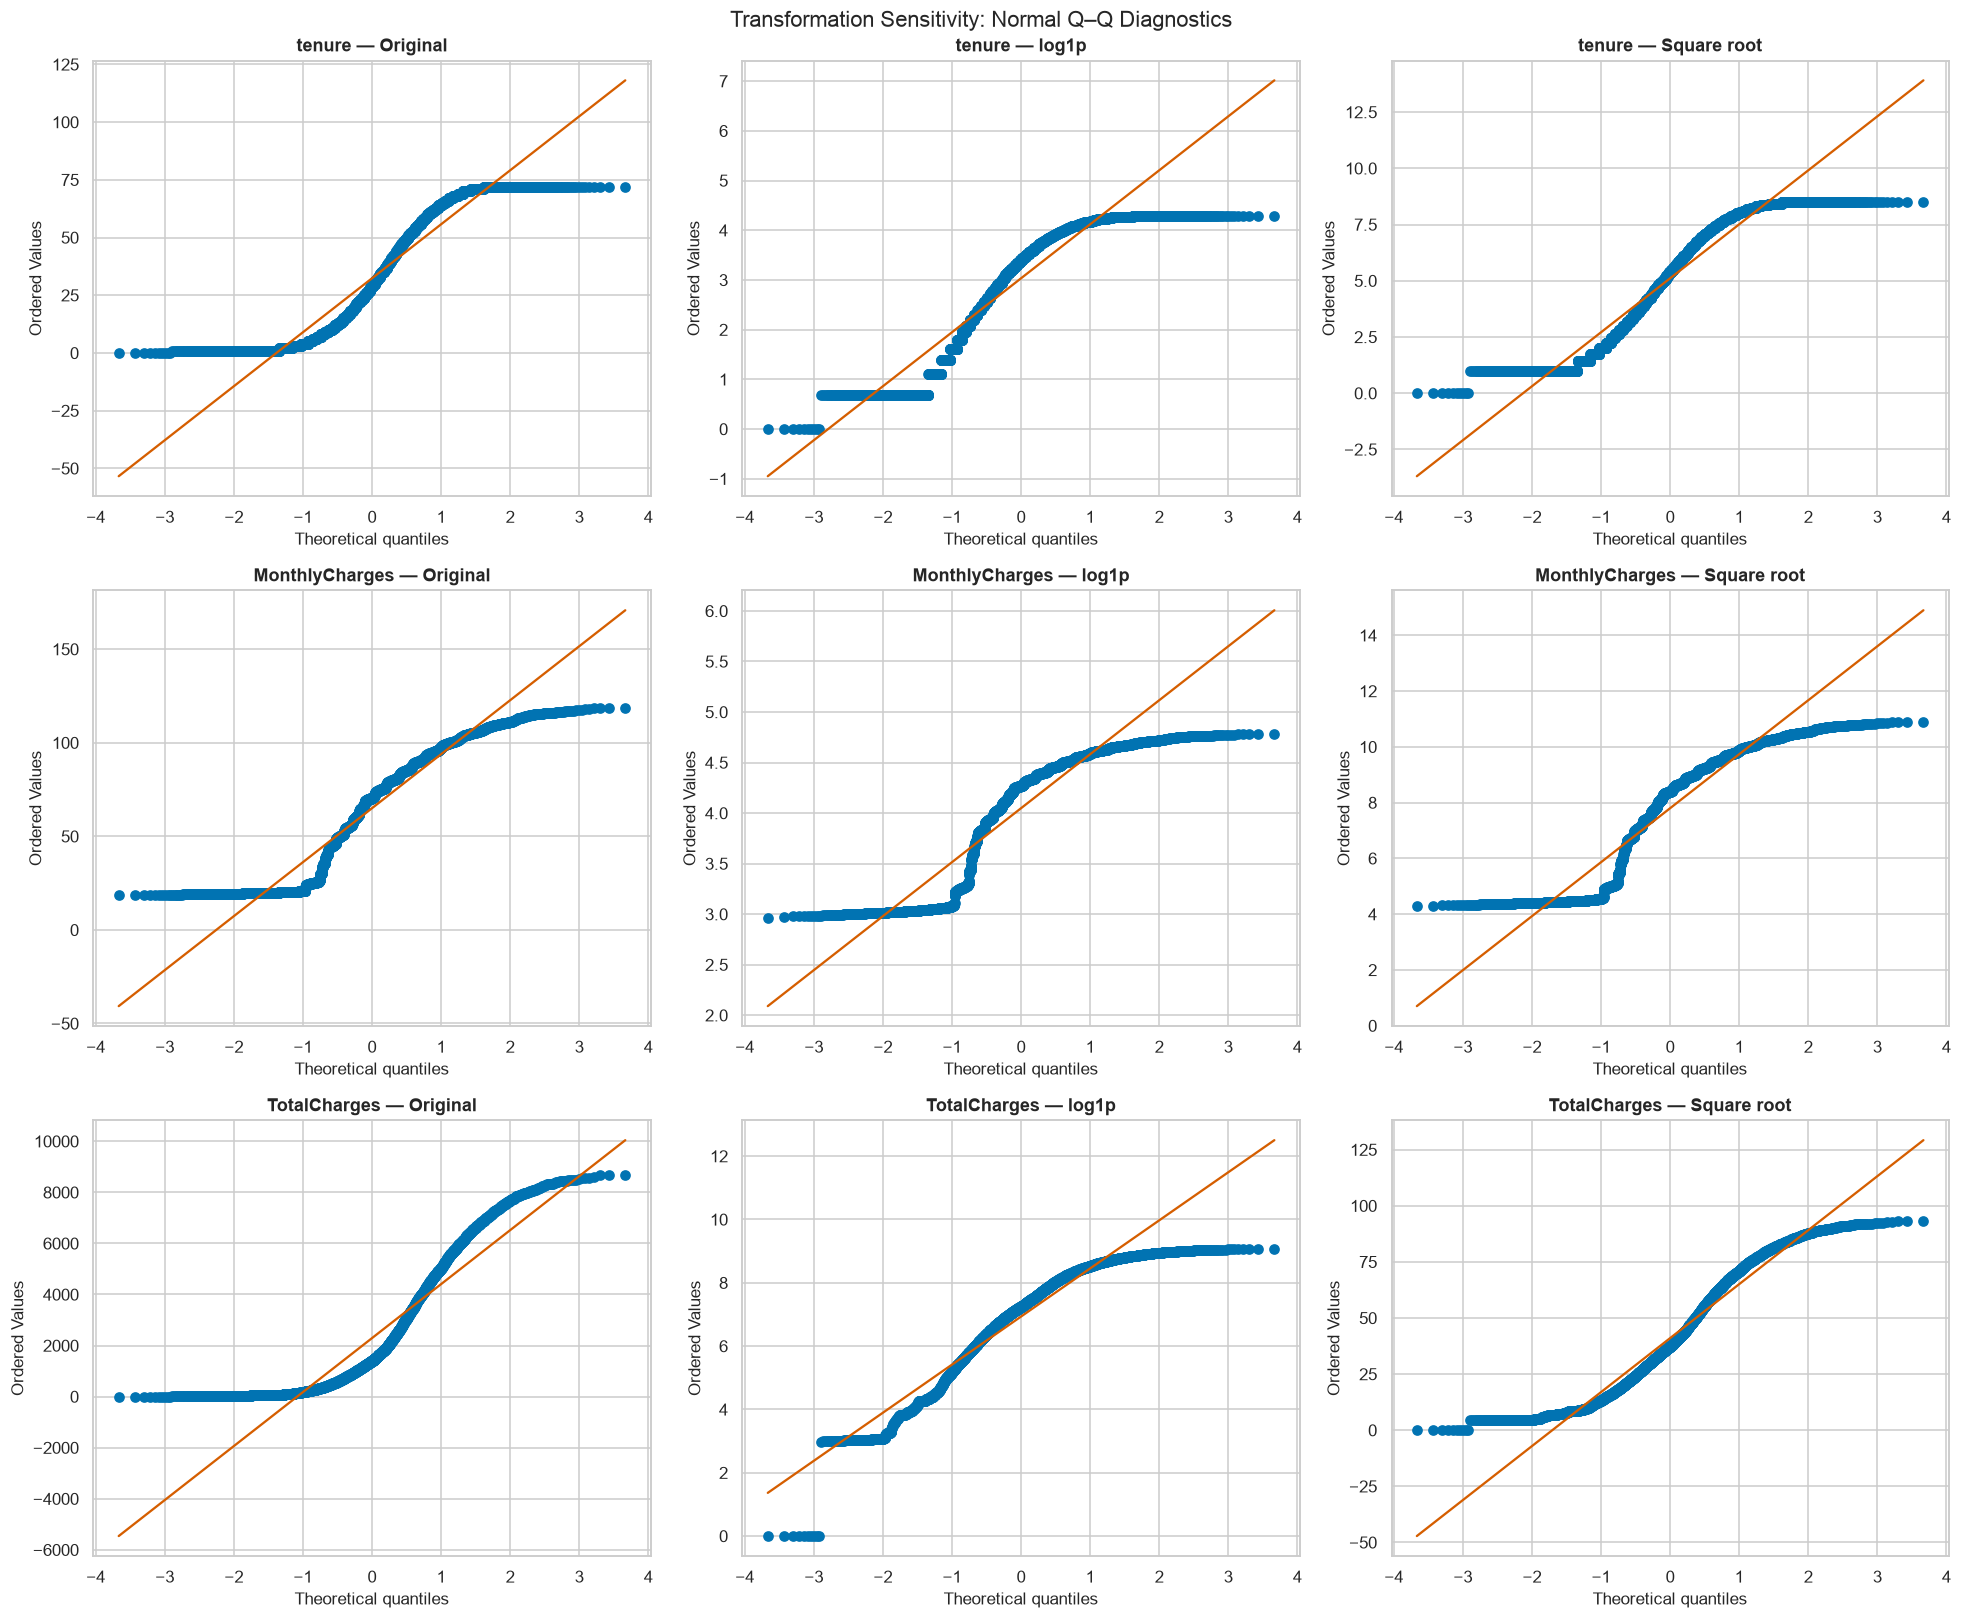

In [13]:
# ruff: noqa: E501
transforms = {"Original": lambda x: x, "log1p": np.log1p, "Square root": np.sqrt}
transformation_rows = []
transformed_for_plot = {}
for feature in numerical_features:
    original = df[feature].to_numpy(float)
    assert np.all(original >= 0)
    churn_mask = df[target_column].eq("Yes").to_numpy()
    for transform_name, transform in transforms.items():
        values = transform(original.copy())
        transformed_for_plot[(feature, transform_name)] = values
        bf = stats.levene(values[churn_mask], values[~churn_mask], center="median")
        transformation_rows.append({"feature": feature, "transformation": transform_name, "skewness": stats.skew(values, bias=False), "excess_kurtosis": stats.kurtosis(values, fisher=True, bias=False), "churned_variance": values[churn_mask].var(ddof=1), "retained_variance": values[~churn_mask].var(ddof=1), "variance_ratio_churned_over_retained": values[churn_mask].var(ddof=1) / values[~churn_mask].var(ddof=1), "brown_forsythe_statistic": bf.statistic, "brown_forsythe_p": bf.pvalue})
transformation_sensitivity = pd.DataFrame(transformation_rows)
display(transformation_sensitivity)

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for row_axes, feature in zip(axes, numerical_features, strict=True):
    for axis, transform_name in zip(row_axes, transforms, strict=True):
        stats.probplot(transformed_for_plot[(feature, transform_name)], dist="norm", plot=axis)
        axis.set_title(f"{feature} — {transform_name}")
fig.suptitle("Transformation Sensitivity: Normal Q–Q Diagnostics")
fig.tight_layout()
plt.show()

## 13. Evidence-based statistical-test selection matrix

The register from Notebook 08 is reproduced as decisions for later work, not executed here.
For means, Welch targets a raw mean difference and tolerates unequal variances. Mann–Whitney
targets relative ranks/stochastic ordering; it does **not** generally test equality of
medians unless group distributions have compatible shapes/spreads and differ mainly by
location. Bootstrap confidence intervals estimate uncertainty for an explicitly chosen
statistic but inherit the sampling unit and source bias.

For categorical association, chi-square is suitable with adequate expected counts; Fisher's
exact test is useful for small suitable contingency tables. For multiple numerical groups,
standard ANOVA targets equal means under equal-variance assumptions, Welch ANOVA relaxes
equal variance, and Kruskal–Wallis targets rank distributions—not automatically medians.
Those omnibus tests remain deferred.

In [14]:
# ruff: noqa: E501
test_selection_rows = [
    ["HYP-01", "Tenure by churn", "binary group → bounded discrete numeric", "1495 / 4139", "tied, bounded, nonnormal", "unequal", "unknown customer independence", "Welch t for mean + bootstrap CI; Mann–Whitney only for rank estimand sensitivity", "mean difference; optionally probability of superiority", "raw mean difference; Hedges g; rank-biserial", "Large samples support mean inference; rank and mean questions differ"],
    ["HYP-02", "MonthlyCharges by churn", "binary group → continuous/rounded numeric", "1495 / 4139", "multimodal/tied, nonnormal", "unequal", "unknown customer independence", "Welch t for mean + bootstrap CI", "mean difference", "raw mean difference; Hedges g", "Product mix and contract confounding; no causal claim"],
    ["HYP-03", "TotalCharges by churn", "binary group → nonnegative skewed numeric", "1495 / 4139", "right-skewed and bounded", "unequal", "unknown customer independence", "Welch t with robust/bootstrap sensitivity; Mann–Whitney for rank question", "mean difference or rank ordering", "raw/standardized mean; probability of superiority", "Tenure structurally drives accumulated charges"],
    ["HYP-04", "Contract and churn", "3-level categorical × binary", "3095 / 1178 / 1361", "not a normality question", "not applicable", "unknown customer independence", "Chi-square association", "independence of categorical variables", "Cramér's V; category risk differences", "EDA-informed; expected counts must be checked later"],
    ["HYP-05", "Internet service and churn", "3-level categorical × binary", "1934 / 2493 / 1207", "not a normality question", "not applicable", "unknown customer independence", "Chi-square association", "categorical independence", "Cramér's V; risk differences", "Structural no-internet category retained"],
    ["HYP-06", "Payment method and churn", "4-level categorical × binary", "1246 / 1215 / 1877 / 1296", "not a normality question", "not applicable", "unknown customer independence", "Chi-square association", "categorical independence", "Cramér's V; risk differences", "Billing/contract composition may confound"],
    ["HYP-07", "Tech support and churn", "3-level categorical × binary", "2786 / 1207 / 1641", "not a normality question", "not applicable", "unknown customer independence", "Chi-square; Fisher exact only if later sparse suitable table", "categorical independence", "Cramér's V; risk differences", "No-internet is structural, not missing"],
    ["HYP-08", "Online security and churn", "3-level categorical × binary", "2816 / 1207 / 1611", "not a normality question", "not applicable", "unknown customer independence", "Chi-square; Fisher exact only if later sparse suitable table", "categorical independence", "Cramér's V; risk differences", "No-internet is structural, not missing"],
    ["HYP-09", "Paperless billing and churn", "binary categorical × binary", "observed development groups", "not a normality question", "not applicable", "unknown customer independence", "Two-proportion/chi-square; Fisher exact if sparse", "risk difference / association", "risk difference; phi", "Unadjusted observational association"],
    ["HYP-10", "Demographics and churn family", "four binary categorical predictors × binary", "observed development groups", "not a normality question", "not applicable", "unknown customer independence", "Separate chi-square/two-proportion tests with later multiplicity control", "family of categorical associations", "phi; risk differences", "Fairness assessment, not discriminatory targeting"],
]
test_selection_columns = ["hypothesis_id", "research_question", "variable_types", "sample_sizes", "distribution_characteristics", "variance_characteristics", "independence_assumption", "candidate_method", "estimand", "effect_size", "limitations"]
test_selection_matrix = pd.DataFrame(test_selection_rows, columns=test_selection_columns)
paperless_counts = df["PaperlessBilling"].value_counts().sort_index()
test_selection_matrix.loc[test_selection_matrix["hypothesis_id"].eq("HYP-09"), "sample_sizes"] = "; ".join(f"{level}={count}" for level, count in paperless_counts.items())
demographic_counts = []
for feature in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    counts = df[feature].value_counts().sort_index()
    demographic_counts.append(feature + ": " + "/".join(f"{level}={count}" for level, count in counts.items()))
test_selection_matrix.loc[test_selection_matrix["hypothesis_id"].eq("HYP-10"), "sample_sizes"] = "; ".join(demographic_counts)
display(test_selection_matrix)

multi_group_method_guide = pd.DataFrame([
    ["Multiple numeric groups, similar variances", "Standard ANOVA", "equality of group means", "eta-squared / omega-squared", "Normal residual/mean approximation, independent groups, homogeneity"],
    ["Multiple numeric groups, unequal variances", "Welch ANOVA", "equality of group means", "heteroscedastic effect-size companion", "Independent groups; robust mean focus"],
    ["Multiple numeric groups, rank question", "Kruskal–Wallis", "equality of rank distributions", "epsilon-squared / pairwise probability measures", "Not automatically a median test; shape differences affect interpretation"],
    ["Complex statistic", "Bootstrap confidence interval", "chosen statistic", "statistic on original scale", "Resampling unit, representativeness, dependence"],
], columns=["scenario", "candidate_method", "estimand", "effect_size", "key_limitation"])
display(multi_group_method_guide)

,hypothesis_id,research_question,variable_types,sample_sizes,distribution_characteristics,variance_characteristics,independence_assumption,candidate_method,estimand,effect_size,limitations
0,HYP-01,Tenure by churn,binary group → bounded discrete numeric,1495 / 4139,"tied, bounded, nonnormal",unequal,unknown customer independence,Welch t for mean + bootstrap CI; Mann–Whitney ...,mean difference; optionally probability of sup...,raw mean difference; Hedges g; rank-biserial,Large samples support mean inference; rank and...
1,HYP-02,MonthlyCharges by churn,binary group → continuous/rounded numeric,1495 / 4139,"multimodal/tied, nonnormal",unequal,unknown customer independence,Welch t for mean + bootstrap CI,mean difference,raw mean difference; Hedges g,Product mix and contract confounding; no causa...
2,HYP-03,TotalCharges by churn,binary group → nonnegative skewed numeric,1495 / 4139,right-skewed and bounded,unequal,unknown customer independence,Welch t with robust/bootstrap sensitivity; Man...,mean difference or rank ordering,raw/standardized mean; probability of superiority,Tenure structurally drives accumulated charges
3,HYP-04,Contract and churn,3-level categorical × binary,3095 / 1178 / 1361,not a normality question,not applicable,unknown customer independence,Chi-square association,independence of categorical variables,Cramér's V; category risk differences,EDA-informed; expected counts must be checked ...
4,HYP-05,Internet service and churn,3-level categorical × binary,1934 / 2493 / 1207,not a normality question,not applicable,unknown customer independence,Chi-square association,categorical independence,Cramér's V; risk differences,Structural no-internet category retained
5,HYP-06,Payment method and churn,4-level categorical × binary,1246 / 1215 / 1877 / 1296,not a normality question,not applicable,unknown customer independence,Chi-square association,categorical independence,Cramér's V; risk differences,Billing/contract composition may confound
6,HYP-07,Tech support and churn,3-level categorical × binary,2786 / 1207 / 1641,not a normality question,not applicable,unknown customer independence,Chi-square; Fisher exact only if later sparse ...,categorical independence,Cramér's V; risk differences,"No-internet is structural, not missing"
7,HYP-08,Online security and churn,3-level categorical × binary,2816 / 1207 / 1611,not a normality question,not applicable,unknown customer independence,Chi-square; Fisher exact only if later sparse ...,categorical independence,Cramér's V; risk differences,"No-internet is structural, not missing"
8,HYP-09,Paperless billing and churn,binary categorical × binary,No=2269; Yes=3365,not a normality question,not applicable,unknown customer independence,Two-proportion/chi-square; Fisher exact if sparse,risk difference / association,risk difference; phi,Unadjusted observational association
9,HYP-10,Demographics and churn family,four binary categorical predictors × binary,gender: Female=2772/Male=2862; SeniorCitizen: ...,not a normality question,not applicable,unknown customer independence,Separate chi-square/two-proportion tests with ...,family of categorical associations,phi; risk differences,"Fairness assessment, not discriminatory targeting"


,scenario,candidate_method,estimand,effect_size,key_limitation
0,"Multiple numeric groups, similar variances",Standard ANOVA,equality of group means,eta-squared / omega-squared,"Normal residual/mean approximation, independen..."
1,"Multiple numeric groups, unequal variances",Welch ANOVA,equality of group means,heteroscedastic effect-size companion,Independent groups; robust mean focus
2,"Multiple numeric groups, rank question",Kruskal–Wallis,equality of rank distributions,epsilon-squared / pairwise probability measures,Not automatically a median test; shape differe...
3,Complex statistic,Bootstrap confidence interval,chosen statistic,statistic on original scale,"Resampling unit, representativeness, dependence"


## 14. Multiple-testing considerations

Many normality and variance diagnostics create many opportunities for small p-values even
when individual null models hold. Here they are exploratory and unadjusted. They should not
be read in isolation or promoted to feature–churn evidence. Large samples make trivial
departures detectable, while small samples may miss material ones. Graphical shape,
effect magnitude, data provenance, the estimand, and method robustness must guide choices.
Formal multiple-testing correction for the registered hypothesis families remains deferred
to Step 10.

## 15. Interview questions with speakable answers

### Q1. Can I use a t-test when raw data are not normally distributed?

**Answer:** Often yes, especially for independent large groups with finite variance. The
t-test concerns the sampling distribution of the mean difference, which can be approximately
normal by the CLT even when observations are skewed. I inspect outliers, dependence, group
size, and variance imbalance; use Welch rather than pooled variance by default; and add a
bootstrap or robust sensitivity analysis when tails or influential points are concerning.

### Q2. Why do normality tests frequently reject large datasets?

**Answer:** Their power increases with sample size, so tiny deviations from an exact normal
model can produce very small p-values. Rejection says the exact model is detectable as
wrong, not that mean inference or a model is unusable. I combine Q–Q plots, skewness,
kurtosis, effect magnitude, and robustness of the downstream estimator.

### Q3. How do Levene, Bartlett, and Brown–Forsythe differ?

**Answer:** Bartlett is efficient under normality but reacts strongly to nonnormality.
Levene tests equality through absolute deviations from group means. Brown–Forsythe is the
median-centered Levene variant and is more resistant to skew and outliers. I prefer
Brown–Forsythe as a diagnostic here, but I do not use any preliminary test as an automatic
gate; Welch directly accommodates unequal variances.

### Q4. How do I choose between Welch's t-test and Mann–Whitney U?

**Answer:** Start with the estimand. Welch tests a difference in population means and allows
unequal variances. Mann–Whitney addresses relative ranks or stochastic ordering and is not
generally a median test unless additional shape/location conditions hold. If the business
question is average charge difference, Welch plus a confidence interval is aligned. If the
question is whether a randomly selected value tends to be larger, a rank method may fit.

## 16. Business and machine-learning interpretation

Distribution diagnostics prevent mechanical test choice. Tenure's bounded lifecycle
structure, charge multimodality, TotalCharges skew, ties, and unequal spreads affect how
summaries and effect sizes should be communicated. They do not establish causal drivers,
independence, or market representativeness. Operational decisions should retain original
units where possible, quantify uncertainty, and distinguish average differences from rank
or tail questions.

Most predictive algorithms do not require normally distributed features. Linear-model
assumptions concern residual/conditional structure rather than marginal input normality;
tree methods need no input-normality assumption. Data leakage, temporal validation,
calibration, drift, and subgroup support are usually more important than forcing feature
histograms into a bell shape.

## 17. Reproducibility, integrity, and scope verification

The final cell checks diagnostic bounds, SciPy critical-value logic, constant/insufficient
handling, seeded simulation invariants, original-frame preservation, input checksum, and
all nine prior notebook hashes. Diagnostic p-values must be finite and within $[0,1]$ when
defined. No held-out or complete validated observations are loaded.

In [15]:
# ruff: noqa: E501
expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
    "09_confidence_interval_analysis.ipynb": "50bf2497adec4d4e5d09502b0849420c9e53d5383615152f51fbc71629fb61c3",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()
frame_fingerprint_after = pd.util.hash_pandas_object(df, index=True).to_numpy()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert configured_development_path.name == "development.parquet"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert np.array_equal(frame_fingerprint_before, frame_fingerprint_after)
assert random_state == 42 and diagnostic_alpha == 0.05 and simulation_repetitions == 500
assert constant_safety["status"] == "insufficient or constant" and insufficient_safety["status"] == "insufficient or constant"
assert constant_variance_safety["status"] == "insufficient or constant"
for column in ["shapiro_p", "dagostino_p", "jarque_bera_p"]:
    assert normality_comparison[column].between(0, 1).all()
assert normality_comparison.loc[normality_comparison["sample_size"].gt(5000), "shapiro_p_value_limited_n_gt_5000"].all()
assert (normality_comparison["anderson_reject_at_5pct"] == (normality_comparison["anderson_statistic"] > normality_comparison["anderson_5pct_critical"])).all()
for column in ["levene_mean_p", "brown_forsythe_p", "bartlett_p"]:
    assert variance_comparison[column].between(0, 1).all()
assert multi_group_variance["brown_forsythe_p"].between(0, 1).all()
assert transformation_sensitivity["brown_forsythe_p"].between(0, 1).all()
assert sample_size_simulation["rejection_frequency"].between(0, 1).all()
assert sample_size_simulation["monte_carlo_se"].between(0, 0.5).all()

repro_rng_1 = np.random.default_rng(random_state)
repro_rng_2 = np.random.default_rng(random_state)
assert np.array_equal(repro_rng_1.normal(size=100), repro_rng_2.normal(size=100))

print("All distribution, normality, variance, simulation, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All distribution, normality, variance, simulation, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
09_confidence_interval_analysis.ipynb,50bf2497adec4d4e5d09502b0849420c9e53d538361515...,50bf2497adec4d4e5d09502b0849420c9e53d538361515...
